# DUNL from first principles: rainfall to runoff

This notebook rebuilds **Deconvolutional Unrolled Neural Learning (DUNL)**
(Tolooshams et al., *Neuron* 2025) from its linear-algebra pieces and applies it to
hourly rainfall and streamflow.

**Why rainfall-runoff is a good first test.** Streamflow is close to a textbook
convolution: rain events (sparse in time) pass through the catchment's response
(the *unit hydrograph*) and add up. So the DUNL model has a physical reading, and
some ground truth is available.

| DUNL (neuroscience) | This notebook (hydrology) |
|---|---|
| neuron `n`, trial `j` | basin, 30-day window |
| spike counts / ΔF/F `y` | streamflow `Q` (mm/h) |
| event onsets (stimulus times) | hours with rain |
| sparse code `x_k` | effective (runoff-producing) rain |
| kernel `h_k` | unit hydrograph (quick flow, slow flow) |
| baseline `a` | baseflow in the window |

**Plan**
1. Setup, logging and data download
2. First look at the data
3. Why the problem is hard (4 short demos)
4. Trials: turning a long series into a data tensor
5. DUNL step by step: operators, step size, prox maps, ISTA, unrolling, training
6. Ground-truth check on synthetic data (including an identifiability test)
7. DUNL on real data: known support, then unknown support
8. Parameter variations
9. Baselines and comparison
10. Summary, log files, and links back to the research questions

**Notation** (same as our notes): `T` time bins per trial, `L` kernel length,
`K` number of kernels, `H` the convolution operator (a Toeplitz matrix),
`Hᵀ` its adjoint (correlation), `x` codes, `a` baseline, `w` a 0/1 mask of observed
bins.

## 1. Setup

Everything the notebook produces goes under one run root:

```
runs_dunl/<timestamp>/
  notebook.log           all log messages (INFO and above)
  environment.json       versions, seed, device
  data_manifest.json     URLs, file sizes, sha256 of downloads
  figures/*.png          every figure in this notebook
  summary.jsonl / .csv   one row per training run (config + metrics)
  <run_name>/            one folder per training run:
      config.json, train_log.jsonl, encoder_trace.jsonl,
      kernels_epoch*.npy, warnings.txt, metrics.json
```

Set `SAVE_TO_DRIVE = True` on Colab to keep these after the session ends.

In [1]:
import importlib.util, subprocess, sys
for pkg, mod in [("xarray", "xarray"), ("netCDF4", "netCDF4")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, json, time, math, hashlib, logging, platform, itertools, urllib.request
from dataclasses import dataclass, asdict, field
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import scipy
from scipy import optimize, signal, stats
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)          # FFT ops below are fastest single-threaded on CPU
DTYPE = torch.float32
DEVICE = "cpu"                    # the problem is small; CPU is enough

SAVE_TO_DRIVE = False
IN_COLAB = "google.colab" in sys.modules
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/dunl_runs"
else:
    BASE_DIR = "runs_dunl"

RUN_ROOT = os.path.join(BASE_DIR, datetime.now().strftime("%Y%m%d_%H%M%S"))
FIG_DIR = os.path.join(RUN_ROOT, "figures")
DATA_DIR = "data_camels_test"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)

# ---- logging: one file for the whole notebook, short lines on screen ----
log = logging.getLogger("dunl")
log.setLevel(logging.DEBUG)
log.handlers.clear()
_fh = logging.FileHandler(os.path.join(RUN_ROOT, "notebook.log"))
_fh.setLevel(logging.DEBUG)
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-7s | %(name)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout)
_sh.setLevel(logging.INFO)
_sh.setFormatter(logging.Formatter("[%(levelname)s] %(message)s"))
log.addHandler(_fh); log.addHandler(_sh)
log.propagate = False

env = dict(python=sys.version.split()[0], numpy=np.__version__, scipy=scipy.__version__,
           pandas=pd.__version__, xarray=xr.__version__, torch=torch.__version__,
           matplotlib=matplotlib.__version__, platform=platform.platform(),
           seed=SEED, dtype=str(DTYPE), device=DEVICE, colab=IN_COLAB)
json.dump(env, open(os.path.join(RUN_ROOT, "environment.json"), "w"), indent=2)
log.info(f"run root: {RUN_ROOT}")
log.debug(f"environment: {env}")

# ---- plotting style: fixed categorical order, thin marks, quiet grid ----
C = dict(rain="#2a78d6", dunl="#eb6834", fir="#1baf7a", gamma="#eda100",
         eta="#e87ba4", gru="#6250d6", truth="#52514e", flow="#0b0b0b",
         alt="#008300", bad="#e34948")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 1.6, "font.size": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "legend.frameon": False,
    "date.converter": "concise",
    "axes.prop_cycle": matplotlib.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

def savefig(fig, name):
    """Save every figure under the run root so results can be compared across runs."""
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, bbox_inches="tight")
    log.debug(f"figure saved: {path}")

[INFO] run root: runs_dunl/20261105_170741


### 1.1 Download the data

We use the small CAMELS-US test set that ships with the `neuralhydrology` package.
It has **hourly** NLDAS forcing (rain, temperature, ...) and **hourly** USGS
streamflow for 4 basins, 2000 to 2002. Both are in mm/h, so rain and flow share
units. The URL is pinned to one commit so the data never changes under us.

Short record, but hourly: about 26,000 time steps per basin, and storm responses
that last hours to days. That is the right scale for a first-principles test.
To scale up later, the same code takes any pair of hourly rain and flow series
(see the appendix).

In [2]:
COMMIT = "9528d1d13eb82c9f038ee489d43784bc7aeb08cc"
BASE_URL = (f"https://raw.githubusercontent.com/neuralhydrology/neuralhydrology/"
            f"{COMMIT}/test/test_data/camels_us")
FILES = {
    "hourly": "hourly/usgs-streamflow-nldas_hourly.nc",
    "names": "camels_attributes_v2.0/camels_name.txt",
    "topo": "camels_attributes_v2.0/camels_topo.txt",
    "clim": "camels_attributes_v2.0/camels_clim.txt",
}

def download(rel_path, retries=3):
    """Download once, cache, and log size and sha256 for provenance."""
    local = os.path.join(DATA_DIR, os.path.basename(rel_path))
    if not os.path.exists(local):
        url = f"{BASE_URL}/{rel_path}"
        for attempt in range(1, retries + 1):
            try:
                urllib.request.urlretrieve(url, local)
                break
            except Exception as e:
                log.warning(f"download failed ({attempt}/{retries}) {url}: {e}")
                if attempt == retries:
                    raise
                time.sleep(2 * attempt)
    sha = hashlib.sha256(open(local, "rb").read()).hexdigest()
    return dict(path=local, url=f"{BASE_URL}/{rel_path}", bytes=os.path.getsize(local), sha256=sha)

manifest = {k: download(v) for k, v in FILES.items()}
json.dump(manifest, open(os.path.join(RUN_ROOT, "data_manifest.json"), "w"), indent=2)
for k, v in manifest.items():
    log.info(f"{k:7s} {v['bytes']/1e6:6.2f} MB  sha256={v['sha256'][:12]}...")

ds = xr.open_dataset(manifest["hourly"]["path"])
log.info(f"hourly dataset: basins={list(ds.basin.values)}, "
         f"{str(ds.date.values[0])[:13]} .. {str(ds.date.values[-1])[:13]}, {ds.sizes['date']} hours")
print(ds)

[INFO] hourly   13.04 MB  sha256=e6e0a9653f36...


[INFO] names     0.03 MB  sha256=f3a85272cd93...


[INFO] topo      0.04 MB  sha256=b64ca9923bca...


[INFO] clim      0.10 MB  sha256=6a3a80256afb...


[INFO] hourly dataset: basins=[np.str_('02064000'), np.str_('01547700'), np.str_('03015500'), np.str_('01022500')], 2000-01-01T00 .. 2002-12-31T23, 26304 hours


<xarray.Dataset> Size: 31MB
Dimensions:                    (basin: 4, date: 26304)
Coordinates:
  * basin                      (basin) <U8 128B '02064000' ... '01022500'
  * date                       (date) datetime64[ns] 210kB 2000-01-01 ... 200...
Data variables: (12/17)
    convective_fraction        (basin, date) float32 421kB ...
    longwave_radiation         (basin, date) float32 421kB ...
    potential_energy           (basin, date) float32 421kB ...
    potential_evaporation      (basin, date) float32 421kB ...
    pressure                   (basin, date) float32 421kB ...
    shortwave_radiation        (basin, date) float32 421kB ...
    ...                         ...
    qobs_mm_per_hour           (basin, date) float32 421kB ...
    qobs_count                 (basin, date) int64 842kB ...
    qualifiers                 (basin, date) <U55 23MB ...
    utcoffset_hours            (basin, date) float32 421kB ...
    rel_deviation_from_camels  (basin, date) float32 421kB ...
  

### 1.2 The four basins

`frac_snow` is the share of precipitation that falls as snow. Snow breaks the
"rain in, flow out" convolution (the response is delayed by weeks), so we prefer a
low value, or we restrict to warm months.

In [3]:
def read_attr(key):
    return pd.read_csv(manifest[key]["path"], sep=";", dtype={"gauge_id": str}).set_index("gauge_id")

attrs = read_attr("names")[["gauge_name"]].join(read_attr("topo")[["area_gages2", "elev_mean", "slope_mean"]])
attrs = attrs.join(read_attr("clim")[["p_mean", "frac_snow", "aridity"]])
attrs = attrs.loc[[str(b) for b in ds.basin.values]]

rows = []
for b in ds.basin.values:
    q = ds.qobs_mm_per_hour.sel(basin=b).values
    p = ds.total_precipitation.sel(basin=b).values
    rows.append(dict(gauge_id=str(b), q_missing=np.isnan(q).mean(), wet_hour_frac=(p > 0.1).mean(),
                     runoff_ratio=np.nanmean(q) / np.nanmean(p)))
basin_table = attrs.join(pd.DataFrame(rows).set_index("gauge_id")).round(3)
basin_table.to_csv(os.path.join(RUN_ROOT, "basin_table.csv"))
basin_table

,gauge_name,area_gages2,elev_mean,slope_mean,p_mean,frac_snow,aridity,q_missing,wet_hour_frac,runoff_ratio
gauge_id,,,,,,,,,,
02064000,"FALLING RIVER NEAR NARUNA, VA",427.77,192.21,9.957,3.095,0.061,0.945,0.098,0.080,0.188
01547700,"Marsh Creek at Blanchard, PA",113.54,353.57,43.026,3.135,0.156,0.749,0.013,0.102,0.374
03015500,"Brokenstraw Creek at Youngsville, PA",784.85,492.56,22.047,3.599,0.192,0.628,0.082,0.129,0.607
01022500,"Narraguagus River at Cherryfield, Maine",573.60,92.68,17.791,3.608,0.245,0.587,0.206,0.083,0.670


**Choice.** We work with **01547700, Marsh Creek at Blanchard, PA**: a small
(114 km²), steep basin with fast responses, only 1.3% missing flow, and a modest
snow share. We use **April to November** to stay away from snowmelt. Change
`BASIN` below to try another one; everything downstream follows.

In [4]:
BASIN = "01547700"
SEASON = list(range(4, 12))       # April..November

Q_all = ds.qobs_mm_per_hour.sel(basin=BASIN).to_series()
P_all = ds.total_precipitation.sel(basin=BASIN).to_series()
Tair_all = ds.temperature.sel(basin=BASIN).to_series()
assert Q_all.index.equals(P_all.index)
assert not P_all.isna().any(), "rain has gaps; the code assumes complete rain"
log.info(f"basin {BASIN}: Q missing {Q_all.isna().mean():.3%}, "
         f"P mean {P_all.mean():.3f} mm/h, Q mean {Q_all.mean():.3f} mm/h")

[INFO] basin 01547700: Q missing 1.289%, P mean 0.100 mm/h, Q mean 0.038 mm/h


## 2. First look at the data

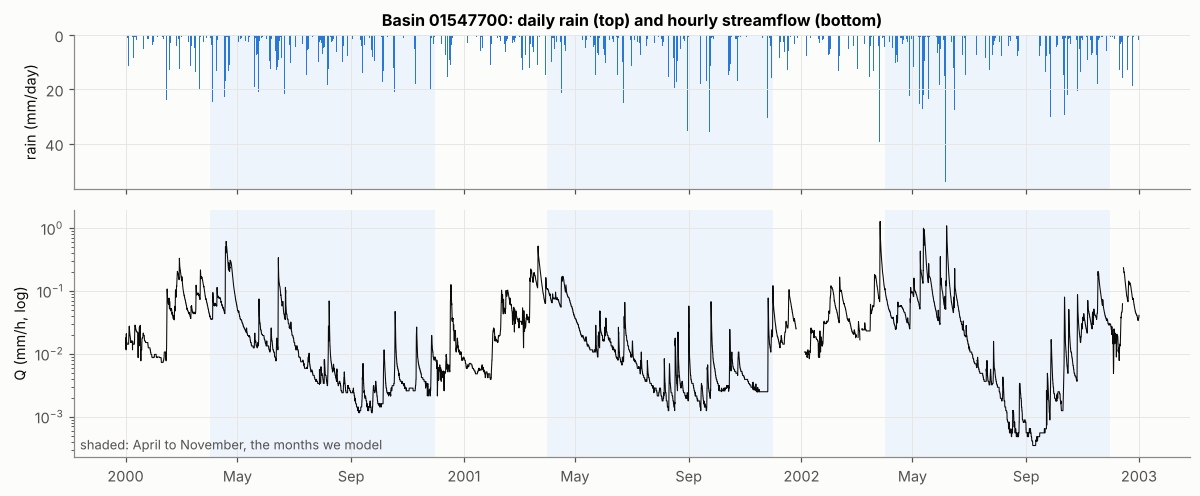

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.6]))
daily_p = P_all.resample("D").sum()
axes[0].bar(daily_p.index, daily_p.values, width=1.0, color=C["rain"])
axes[0].invert_yaxis(); axes[0].set_ylabel("rain (mm/day)")
axes[0].set_title(f"Basin {BASIN}: daily rain (top) and hourly streamflow (bottom)")
axes[1].plot(Q_all.index, Q_all.values, color=C["flow"], lw=0.7)
axes[1].set_yscale("log"); axes[1].set_ylabel("Q (mm/h, log)")
for yr in [2000, 2001, 2002]:
    for ax in axes:
        ax.axvspan(pd.Timestamp(f"{yr}-04-01"), pd.Timestamp(f"{yr}-12-01"), color="#eef4fc", zorder=0, lw=0)
axes[1].text(0.005, 0.03, "shaded: April to November, the months we model", transform=axes[1].transAxes,
             color="#52514e", fontsize=8.5)
fig.tight_layout(); savefig(fig, "02_overview"); plt.show()

Zoom into one month. Look at how storms arrive before the previous response has
faded: the observed flow is a **sum of overlapping responses**.

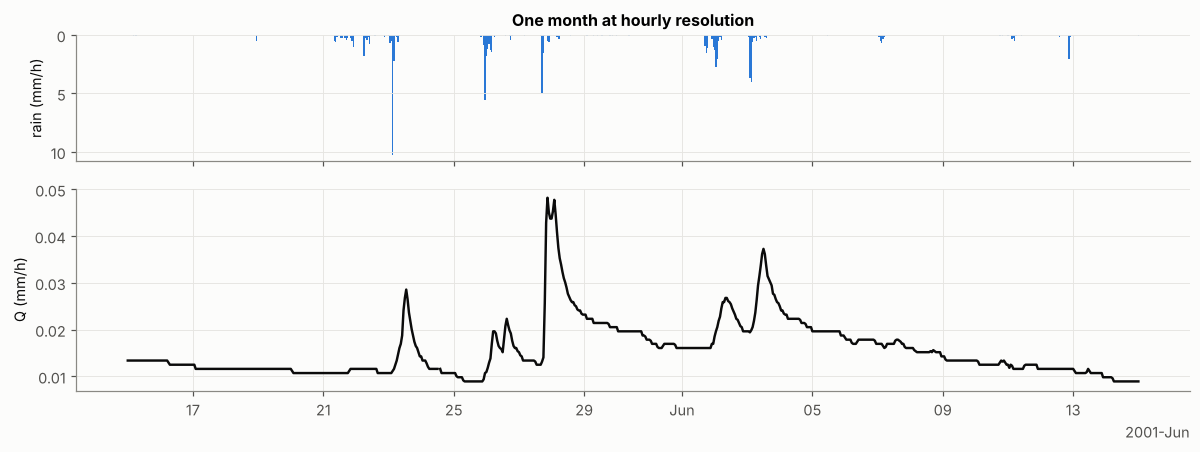

In [6]:
z0, z1 = pd.Timestamp("2001-05-15"), pd.Timestamp("2001-06-15")
fig, axes = plt.subplots(2, 1, figsize=(11, 4.2), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.6]))
pz, qz = P_all[z0:z1], Q_all[z0:z1]
axes[0].bar(pz.index, pz.values, width=1 / 24, color=C["rain"]); axes[0].invert_yaxis()
axes[0].set_ylabel("rain (mm/h)"); axes[0].set_title("One month at hourly resolution")
axes[1].plot(qz.index, qz.values, color=C["flow"]); axes[1].set_ylabel("Q (mm/h)")
fig.tight_layout(); savefig(fig, "02_zoom"); plt.show()

Seasonality: the same rain gives much less flow in summer (high evaporation, dry
soils). This is the first sign that the system is **not time invariant**, which is
one of DUNL's core assumptions. The amplitude of each event can absorb part of it;
the shape cannot.

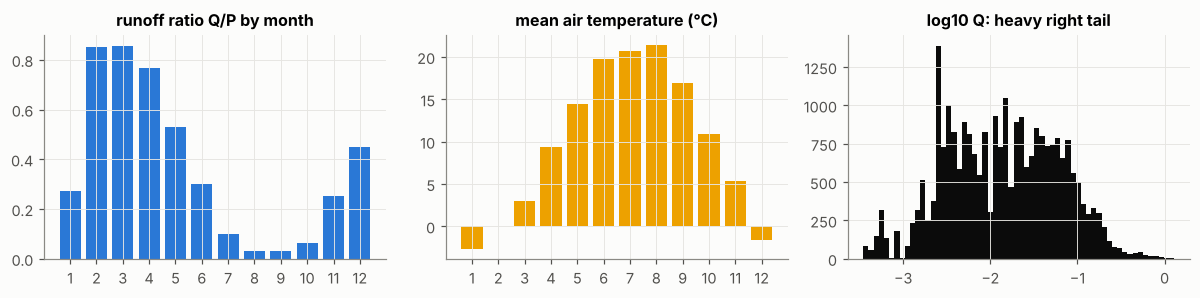

[INFO] monthly runoff ratio: 1:0.27, 2:0.85, 3:0.86, 4:0.77, 5:0.53, 6:0.30, 7:0.10, 8:0.03, 9:0.03, 10:0.06, 11:0.25, 12:0.45


In [7]:
m = pd.DataFrame(dict(P=P_all, Q=Q_all, T=Tair_all))
monthly = m.groupby(m.index.month).agg(P=("P", "mean"), Q=("Q", "mean"), T=("T", "mean"))
monthly["runoff_ratio"] = monthly.Q / monthly.P
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
axes[0].bar(monthly.index, monthly.runoff_ratio, color=C["rain"]); axes[0].set_title("runoff ratio Q/P by month")
axes[1].bar(monthly.index, monthly["T"], color=C["gamma"]); axes[1].set_title("mean air temperature (°C)")
qpos = Q_all.dropna()
axes[2].hist(np.log10(qpos), bins=60, color=C["flow"]); axes[2].set_title("log10 Q: heavy right tail")
for ax in axes[:2]: ax.set_xticks(range(1, 13))
fig.tight_layout(); savefig(fig, "02_seasonality"); plt.show()
log.info("monthly runoff ratio: " + ", ".join(f"{i}:{v:.2f}" for i, v in monthly.runoff_ratio.items()))

### 2.1 Storms

We cut the rain series into storms: wet hours (`P > 0.1 mm/h`) separated by at
least 6 dry hours. Storms with less than 2 mm are ignored. For each storm we record
depth, onset, and an **antecedent wetness** index (log of mean flow in the 24 h
before onset). The storm table is used for the analysis later.

In [8]:
WET_THR, STORM_GAP, STORM_MIN = 0.1, 6, 2.0

def find_storms(p, wet_thr=WET_THR, gap=STORM_GAP, min_depth=STORM_MIN):
    wet = (p.values > wet_thr).astype(int)
    idx = np.flatnonzero(wet)
    if len(idx) == 0:
        return pd.DataFrame()
    breaks = np.flatnonzero(np.diff(idx) > gap)
    starts = np.r_[idx[0], idx[breaks + 1]]; ends = np.r_[idx[breaks], idx[-1]]
    out = []
    for s, e in zip(starts, ends):
        depth = p.values[s:e + 1].sum()
        if depth >= min_depth:
            out.append(dict(i_start=s, i_end=e, start=p.index[s], dur_h=e - s + 1, depth_mm=depth))
    return pd.DataFrame(out)

storms = find_storms(P_all)
q_np = Q_all.values
storms["q_pre"] = [np.nanmean(q_np[max(0, s - 24):s]) if s > 0 and np.isfinite(q_np[max(0, s - 24):s]).any()
                   else np.nan for s in storms.i_start]
storms["log_q_pre"] = np.log10(storms.q_pre)
storms["gap_to_next_h"] = np.r_[storms.i_start.values[1:] - storms.i_end.values[:-1], np.nan]
storms["in_season"] = storms.start.dt.month.isin(SEASON)
storms.to_csv(os.path.join(RUN_ROOT, "storms.csv"), index=False)
log.info(f"{len(storms)} storms (>= {STORM_MIN} mm), {storms.in_season.sum()} in season; "
         f"median depth {storms.depth_mm.median():.1f} mm, median duration {storms.dur_h.median():.0f} h")
storms.head()

[INFO] 208 storms (>= 2.0 mm), 145 in season; median depth 8.0 mm, median duration 11 h


,i_start,i_end,start,dur_h,depth_mm,q_pre,log_q_pre,gap_to_next_h,in_season
0,75,89,2000-01-04 03:00:00,15,11.521654,0.014286,-1.845083,137.0,False
1,226,244,2000-01-10 10:00:00,19,8.001570,0.014286,-1.845083,220.0,False
2,464,488,2000-01-20 08:00:00,25,5.450416,0.019848,-1.702280,101.0,False
3,589,612,2000-01-25 13:00:00,24,3.057701,0.014528,-1.837794,101.0,False
4,713,730,2000-01-30 17:00:00,18,6.069333,0.008769,-2.057055,315.0,False


## 3. Why this is hard

Four short demos. Each one is a reason why simple methods fail and what DUNL is
built to handle.

### 3a. Responses overlap

If the next storm usually starts before the previous response has decayed, no
window around a storm contains that storm's response alone. Below: the gap from
the end of one storm to the start of the next, against the kernel length we will
use (`L = 120 h`, chosen in Section 8).

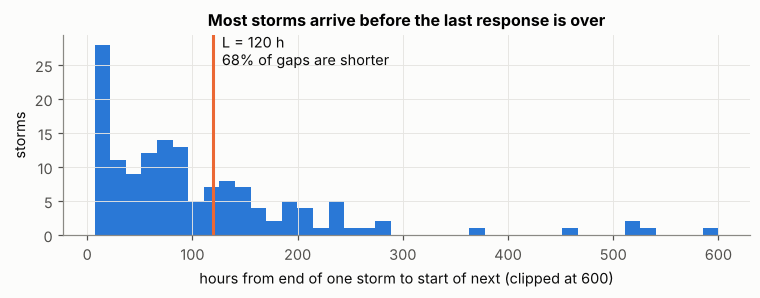

[INFO] overlap: 67.6% of in-season inter-storm gaps < 120 h


In [9]:
L_DEFAULT = 120
gaps = storms.loc[storms.in_season, "gap_to_next_h"].dropna()
frac_overlap = (gaps < L_DEFAULT).mean()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(gaps.clip(upper=600), bins=40, color=C["rain"])
ax.axvline(L_DEFAULT, color=C["dunl"], lw=2)
ax.text(L_DEFAULT + 8, ax.get_ylim()[1] * 0.85, f"L = {L_DEFAULT} h\n{frac_overlap:.0%} of gaps are shorter",
        color="#0b0b0b")
ax.set_xlabel("hours from end of one storm to start of next (clipped at 600)"); ax.set_ylabel("storms")
ax.set_title("Most storms arrive before the last response is over")
fig.tight_layout(); savefig(fig, "03a_overlap"); plt.show()
log.info(f"overlap: {frac_overlap:.1%} of in-season inter-storm gaps < {L_DEFAULT} h")

### 3b. Averaging around events is biased

The classical move (like a PSTH) is to align flow at storm onsets and average.
Below we do it twice: over all storms, and over *isolated* storms only (no other
storm within `L` hours before or after). If responses did not overlap, the two
curves would match. They do not:

* the all-storm average carries the tails of neighbouring storms (the bump at
  40 to 70 h is the *next* storm, not this one);
* isolated storms are rare (about 1 in 10) and mostly fall in dry summer weeks,
  so their response is tiny and sits on a falling recession, which drags the
  curve below zero.

So averaging gives a biased answer *and* the bias depends on which events you keep.

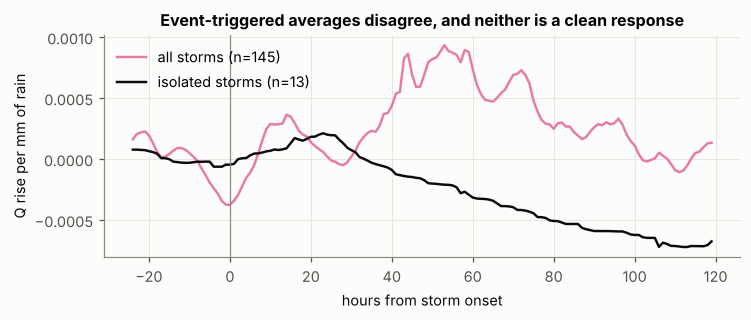

[INFO] ETA: all n=145, isolated n=13; only 9% of storms are isolated


In [10]:
def event_triggered_average(q, storms_df, L, pre=24):
    segs = []
    for s, d in zip(storms_df.i_start, storms_df.depth_mm):
        if s - pre < 0 or s + L > len(q):
            continue
        seg = q[s - pre:s + L]
        if np.isnan(seg).mean() > 0.1:
            continue
        base = np.nanmean(q[s - pre:s])
        segs.append((seg - base) / d)                # response per mm of rain
    segs = np.array(segs)
    return np.nanmean(segs, 0), len(segs)

ss = storms[storms.in_season]
prev_gap = np.r_[np.nan, ss.i_start.values[1:] - ss.i_end.values[:-1]]
isolated = ss[(ss.gap_to_next_h > L_DEFAULT) & (prev_gap > L_DEFAULT)]
eta_all, n_all = event_triggered_average(q_np, ss, L_DEFAULT)
eta_iso, n_iso = event_triggered_average(q_np, isolated, L_DEFAULT)
lags = np.arange(-24, L_DEFAULT)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(lags, eta_all, color=C["eta"], label=f"all storms (n={n_all})")
ax.plot(lags, eta_iso, color=C["flow"], label=f"isolated storms (n={n_iso})")
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_xlabel("hours from storm onset"); ax.set_ylabel("Q rise per mm of rain")
ax.set_title("Event-triggered averages disagree, and neither is a clean response"); ax.legend()
fig.tight_layout(); savefig(fig, "03b_eta"); plt.show()
log.info(f"ETA: all n={n_all}, isolated n={n_iso}; only {n_iso/max(n_all,1):.0%} of storms are isolated")

### 3c. Deconvolution is ill-conditioned

Write the forward map as a matrix, `y = H x`, where `H` is Toeplitz with a smooth,
positive kernel. The singular values of `H` follow `|ĥ(ω)|`, the kernel's frequency
response, which falls fast: the catchment is a **low-pass filter**. Inverting it
multiplies high-frequency noise by `1 / |ĥ(ω)|`, which is huge.

Least squares on `y = Hx + noise` gives a wild, negative, useless `x`. Adding what
we know (codes are **sparse** and **non-negative**) fixes it. That prior is the
whole reason DUNL works.

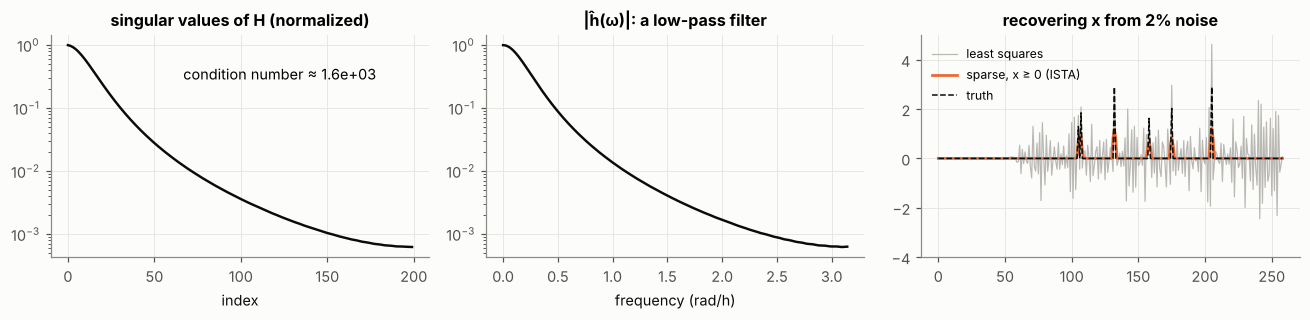

[INFO] ill-posedness demo: cond(H)=1.59e+03, LS error=2.43, ISTA error=0.71


In [11]:
def gamma_kernel(L, n_shape, scale_h):
    """Unit-mass gamma (Nash cascade) kernel on hourly bins: exact integral over each hour."""
    edges = np.arange(L + 1, dtype=float)
    k = np.diff(stats.gamma.cdf(edges, a=n_shape, scale=scale_h))
    return k / k.sum()

def toeplitz_H(h, T):
    """Dense 'full' convolution matrix: codes of length T+L-1 -> signal of length T."""
    L = len(h); Hm = np.zeros((T, T + L - 1))
    for s in range(T + L - 1):
        for l in range(L):
            t = s + l - (L - 1)
            if 0 <= t < T:
                Hm[t, s] = h[l]
    return Hm

rng = np.random.default_rng(1)
h_demo = gamma_kernel(60, 3.0, 4.0); h_demo /= np.linalg.norm(h_demo)
T_demo = 200
Hm = toeplitz_H(h_demo, T_demo)
svals = np.linalg.svd(Hm, compute_uv=False)
x_true = np.zeros(T_demo + 59); x_true[rng.choice(np.arange(60, T_demo + 40), 6, replace=False)] = rng.uniform(1, 3, 6)
y_clean = Hm @ x_true; y_noisy = y_clean + 0.02 * y_clean.std() * rng.standard_normal(T_demo)
x_ls = np.linalg.lstsq(Hm, y_noisy, rcond=None)[0]
lam_demo = 0.02 * np.abs(Hm.T @ y_noisy).max()
x_ista = np.zeros_like(x_true); step = 1 / svals[0] ** 2
for _ in range(3000):
    x_ista = np.maximum(x_ista - step * Hm.T @ (Hm @ x_ista - y_noisy) - step * lam_demo, 0)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].semilogy(svals / svals[0], color=C["flow"]); axes[0].set_title("singular values of H (normalized)")
axes[0].set_xlabel("index"); axes[0].text(0.35, 0.8, f"condition number ≈ {svals[0]/svals[-1]:.1e}",
                                           transform=axes[0].transAxes)
w_ = np.linspace(0, np.pi, 400); Hw = np.abs(np.fft.rfft(h_demo, 798))
axes[1].semilogy(np.linspace(0, np.pi, len(Hw)), Hw / Hw.max(), color=C["flow"])
axes[1].set_title("|ĥ(ω)|: a low-pass filter"); axes[1].set_xlabel("frequency (rad/h)")
axes[2].plot(x_ls, color="#b9b8b3", lw=0.8, label="least squares")
axes[2].plot(x_ista, color=C["dunl"], lw=1.8, label="sparse, x ≥ 0 (ISTA)")
axes[2].plot(x_true, color=C["flow"], lw=1.0, ls="--", label="truth")
axes[2].set_ylim(-4, 5); axes[2].set_title("recovering x from 2% noise"); axes[2].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "03c_illposed"); plt.show()
log.info(f"ill-posedness demo: cond(H)={svals[0]/svals[-1]:.2e}, "
         f"LS error={np.linalg.norm(x_ls-x_true)/np.linalg.norm(x_true):.2f}, "
         f"ISTA error={np.linalg.norm(x_ista-x_true)/np.linalg.norm(x_true):.2f}")

### 3d. The response is not time invariant

DUNL assumes a fixed kernel shape, with only the amplitude changing per event.
Below: storm runoff ratio (window estimate) against antecedent wetness. Storms of
similar depth produce very different volumes depending on how wet the basin was.
That is fine for DUNL as long as it shows up in the **amplitude**. Whether the
**shape** also changes is a question we return to in Section 10.

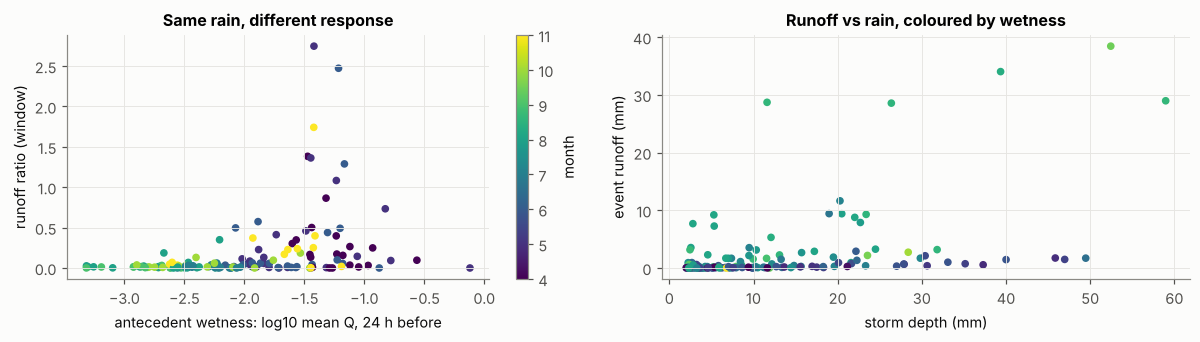

[INFO] window runoff ratio vs antecedent wetness: Spearman 0.39 (p=1.3e-06)


In [12]:
def window_runoff_ratio(q, s, depth, L):
    seg = q[s:s + L]
    if np.isnan(seg).mean() > 0.2:
        return np.nan
    base = np.nanmean(q[max(0, s - 6):s + 1])
    return np.nansum(np.clip(seg - base, 0, None)) / depth

ss = storms[storms.in_season].copy()
ss["rr_window"] = [window_runoff_ratio(q_np, s, d, L_DEFAULT) for s, d in zip(ss.i_start, ss.depth_mm)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sc = axes[0].scatter(ss.log_q_pre, ss.rr_window, c=ss.start.dt.month, cmap="viridis", s=16)
axes[0].set_xlabel("antecedent wetness: log10 mean Q, 24 h before"); axes[0].set_ylabel("runoff ratio (window)")
axes[0].set_title("Same rain, different response"); plt.colorbar(sc, ax=axes[0], label="month")
axes[1].scatter(ss.depth_mm, ss.rr_window * ss.depth_mm, c=ss.log_q_pre, cmap="viridis", s=16)
axes[1].set_xlabel("storm depth (mm)"); axes[1].set_ylabel("event runoff (mm)")
axes[1].set_title("Runoff vs rain, coloured by wetness")
fig.tight_layout(); savefig(fig, "03d_nonlti"); plt.show()
rho = stats.spearmanr(ss.log_q_pre, ss.rr_window, nan_policy="omit")
log.info(f"window runoff ratio vs antecedent wetness: Spearman {rho.statistic:.2f} (p={rho.pvalue:.1e})")

## 4. Trials: from a long series to a data tensor

DUNL works on a batch of trials `Y ∈ R^{J × T}`. Here a trial is a 30-day window
(`T = 720 h`) inside April to November, with at most 10% missing flow.

Three details matter:

1. **Rain before the window.** A storm 3 days before the window still shapes its
   first hours. So each trial keeps `L_max - 1` hours of rain *context* before it,
   and the codes cover times `-(L-1) .. T-1` ("full" convolution). Without this the
   model must explain the start of each window with the baseline alone.
2. **Missing flow.** We keep a 0/1 mask `w` and use it in the loss and in the
   gradient: `w ⊙ (Hx + a - y)`. This is the "missing data" extension that the paper
   lists as a limitation; with a mask it costs nothing.
3. **Scale.** Flow is divided by its training standard deviation so that the
   regularization weights mean the same thing across basins.

Split by year: **2000 and 2001 for training** (every 4th of those windows held out
for validation, chosen so validation includes wet May windows, not only dry
summer ones), **2002 for testing**.

[INFO] trials: 24 total | train=12, test=8, val=4 | Q_SCALE=0.0562 mm/h


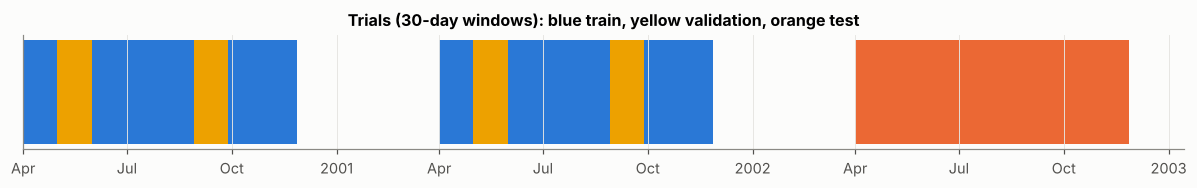

In [13]:
T_TRIAL, L_MAX, MAX_MISSING = 720, 240, 0.10

def build_trials(q, p, T=T_TRIAL, Lmax=L_MAX, season=SEASON, max_missing=MAX_MISSING):
    starts, i = [], Lmax
    while i + T <= len(q):
        win = q.iloc[i:i + T]
        if win.index.month.isin(season).all() and win.isna().mean() <= max_missing:
            starts.append(i); i += T
        else:
            i += 24
    return np.array(starts)

starts = build_trials(Q_all, P_all)
years = np.array([Q_all.index[s].year for s in starts])
split = np.where(years == 2002, "test", "train")
tr_idx = np.flatnonzero(split == "train")
split[tr_idx[1::4]] = "val"          # every 4th training window, offset so May (wet) windows are included

Q_SCALE = float(np.nanstd(np.concatenate([q_np[s:s + T_TRIAL] for s in starts[split == "train"]])))
Y_np = np.stack([q_np[s:s + T_TRIAL] for s in starts]) / Q_SCALE
W_np = (~np.isnan(Y_np)).astype(np.float32); Y_np = np.nan_to_num(Y_np)
P_ctx_np = np.stack([P_all.values[s - L_MAX + 1:s + T_TRIAL] for s in starts])   # (J, T+Lmax-1)

trials = pd.DataFrame(dict(start=Q_all.index[starts], i_start=starts, split=split,
                           missing=1 - W_np.mean(1), rain_mm=P_ctx_np[:, L_MAX - 1:].sum(1)))
trials.to_csv(os.path.join(RUN_ROOT, "trials.csv"), index=False)
log.info(f"trials: {len(starts)} total | " + ", ".join(f"{k}={v}" for k, v in trials.split.value_counts().items())
         + f" | Q_SCALE={Q_SCALE:.4f} mm/h")

def to_t(a):
    return torch.tensor(a, dtype=DTYPE, device=DEVICE)

def subset(name, L):
    """Tensors for one split. Rain context is cut to L-1 hours so codes cover -(L-1)..T-1."""
    sel = trials.split.values == name
    pc = P_ctx_np[sel][:, L_MAX - L:]
    return dict(Y=to_t(Y_np[sel]), W=to_t(W_np[sel]), P=to_t(pc),
                S=to_t((pc > WET_THR).astype(np.float32)), idx=np.flatnonzero(sel))

fig, ax = plt.subplots(figsize=(11, 1.8))
for (s, sp) in zip(trials.start, trials.split):
    ax.barh(0, pd.Timedelta(hours=T_TRIAL), left=s, height=0.6,
            color={"train": C["rain"], "val": C["gamma"], "test": C["dunl"]}[sp])
ax.set_yticks([]); ax.set_title("Trials (30-day windows): blue train, yellow validation, orange test")
fig.tight_layout(); savefig(fig, "04_trials"); plt.show()

## 5. DUNL step by step

### 5.1 The operators `H` and `Hᵀ`

For one kernel `h ∈ R^L` and codes `x ∈ R^{T+L-1}` (time `-(L-1) .. T-1`):

```
(H x)[t]  = Σ_l h[l] x[t + (L-1) - l],       t = 0..T-1
(Hᵀ r)[s] = Σ_l h[l] r[s - (L-1) + l]        (correlation, the adjoint)
```

With K kernels, `H = [H_1 | ... | H_K]` and `Hᵀ r = [h_1 ⋆ r ; ... ; h_K ⋆ r]`.

Two implementations:

* **direct**: `conv_transpose1d` for `H`, `conv1d` for `Hᵀ`. Easy to read.
* **FFT**: embed the Toeplitz matrix in a circulant one, which the DFT
  diagonalizes: `H x = crop(F⁻¹(ĥ · x̂))` and `Hᵀ r = crop(F⁻¹(conj(ĥ) · r̂))`.
  Cost `O(N log N)` regardless of `L`. About 5x faster here on CPU.

We check both against each other and check the **adjoint identity**
`⟨Hx, r⟩ = ⟨x, Hᵀr⟩`. A wrong adjoint gives a wrong gradient and a silent failure,
so this test runs before anything else.

In [14]:
def H_direct(x, h, T):
    """x: (B,K,T+L-1), h: (K,L) -> (B,T)."""
    L = h.shape[1]
    return F.conv_transpose1d(x, h.unsqueeze(1))[:, 0, L - 1:L - 1 + T]

def Ht_direct(r, h):
    """r: (B,T), h: (K,L) -> (B,K,T+L-1)."""
    L = h.shape[1]
    return F.conv1d(F.pad(r.unsqueeze(1), (L - 1, L - 1)), h.unsqueeze(1))

def _nfft(T, L):
    n = T + 2 * L - 2
    return 1 << (n - 1).bit_length()

def H_fft(x, h, T):
    L = h.shape[1]; N = _nfft(T, L)
    Xf = torch.fft.rfft(x, N); Hf = torch.fft.rfft(h, N)
    return torch.fft.irfft((Xf * Hf.unsqueeze(0)).sum(1), N)[:, L - 1:L - 1 + T]

def Ht_fft(r, h):
    L = h.shape[1]; T = r.shape[1]; N = _nfft(T, L)
    Rf = torch.fft.rfft(F.pad(r, (L - 1, L - 1)), N); Hf = torch.fft.rfft(h, N)
    return torch.fft.irfft(Rf.unsqueeze(1) * Hf.conj().unsqueeze(0), N)[:, :, :T + L - 1]

OPS = {"direct": (H_direct, Ht_direct), "fft": (H_fft, Ht_fft)}

def check_operators(K=2, L=120, T=720, B=4):
    g = torch.Generator().manual_seed(0)
    h = torch.rand(K, L, generator=g, dtype=torch.float64)
    x = torch.randn(B, K, T + L - 1, generator=g, dtype=torch.float64)
    r = torch.randn(B, T, generator=g, dtype=torch.float64)
    out = {}
    for name, (Hop, Htop) in OPS.items():
        out[f"adjoint_err_{name}"] = abs(((Hop(x, h, T) * r).sum() - (x * Htop(r, h)).sum()).item())
    out["H_fft_vs_direct"] = (H_fft(x, h, T) - H_direct(x, h, T)).abs().max().item()
    out["Ht_fft_vs_direct"] = (Ht_fft(r, h) - Ht_direct(r, h)).abs().max().item()
    hf, xf = h.float(), x.float()
    for name, (Hop, Htop) in OPS.items():
        t0 = time.perf_counter()
        for _ in range(50):
            Htop(Hop(xf, hf, T), hf)
        out[f"ms_per_H_Ht_{name}"] = 1e3 * (time.perf_counter() - t0) / 50
    return out

op_check = check_operators()
for k, v in op_check.items():
    log.info(f"operator check  {k:22s} {v:.3e}")
assert op_check["adjoint_err_direct"] < 1e-8 and op_check["adjoint_err_fft"] < 1e-8, "adjoint test failed"
assert op_check["H_fft_vs_direct"] < 1e-8, "FFT and direct convolution disagree"
H_op, Ht_op = OPS["fft"]

[INFO] operator check  adjoint_err_direct     2.274e-13


[INFO] operator check  adjoint_err_fft        0.000e+00


[INFO] operator check  H_fft_vs_direct        2.043e-14


[INFO] operator check  Ht_fft_vs_direct       1.421e-14


[INFO] operator check  ms_per_H_Ht_direct     2.468e+00


[INFO] operator check  ms_per_H_Ht_fft        2.926e-01


### 5.2 Step size

ISTA takes gradient steps on `f(x) = ½‖w ⊙ (Hx + a - y)‖²`. Its gradient
`Hᵀ(w ⊙ (Hx + a - y))` is Lipschitz with constant `ℓ = ‖H‖₂² · sup g'`, and
`sup g' = 1` for the Gaussian (identity link). The step must satisfy `α ≤ 1/ℓ`.

Two ways to get `‖H‖₂² = σ_max(H)²`:

* **power method** on `HᵀH` (this is what the paper's Algorithm 1 computes);
* **Fourier bound**: `‖H‖₂² ≤ sup_ω Σ_k |ĥ_k(ω)|²`, exact for the infinite
  Toeplitz operator and a tight upper bound for the finite one. One FFT, no
  iterations, so we can recompute it every training step.

**A check on the paper.** Its text says `α < 1/σ_max(H)`. For a positive kernel
with `‖h‖₂ = 1`, `σ_max ≈ Σ h` can be about 8 here, so `1/σ` is 8 times larger than
`1/σ²`. The experiment below runs ISTA with several steps on a real trial.

[INFO] gamma kernel (unit l2): sigma^2 Fourier=16.049, power=16.039, sigma=4.005


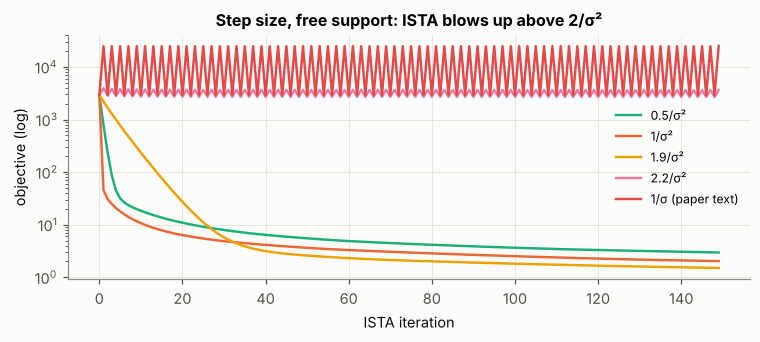

[INFO] final objective by step (free support): 0.5/σ²: 2.96, 1/σ²: 2.03, 1.9/σ²: 1.5, 2.2/σ²: 3.64e+03, 1/σ (paper text): 2.48e+04


[INFO] known support on this trial: ‖H E‖² = 14.056 vs ‖H‖² = 16.039 (ratio 0.88); a support-aware step can be 1.1x larger


In [15]:
def sigma2_fourier(h, nfft=8192):
    Hf = torch.fft.rfft(h.detach(), n=nfft, dim=1)
    return float((Hf.abs() ** 2).sum(0).max())

def sigma2_power(h, T, iters=300, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(1, h.shape[0], T + h.shape[1] - 1, generator=g, dtype=h.dtype)
    for _ in range(iters):
        x = x / x.norm()
        x = Ht_op(H_op(x, h.detach(), T), h.detach())
    return float(x.norm())

def sigma2_power_masked(h, T, support, iters=40, seed=0):
    """Per-trial ‖H E_j‖², where E_j keeps only the code positions allowed in trial j.
    With known support the encoder only moves inside that subspace, so this smaller
    constant is the one that matters, and it permits a larger, faster step."""
    g = torch.Generator().manual_seed(seed)
    h = h.detach(); B = support.shape[0]; e = support[:, None, :]
    x = torch.rand(B, h.shape[0], T + h.shape[1] - 1, generator=g, dtype=h.dtype) * e
    nrm = torch.ones(B, dtype=h.dtype)
    for _ in range(iters):
        x = x / x.flatten(1).norm(dim=1).clamp_min(1e-12)[:, None, None]
        x = Ht_op(H_op(x, h, T), h) * e
        nrm = x.flatten(1).norm(dim=1)
    return nrm.clamp_min(1e-12)

h_g = to_t(gamma_kernel(L_DEFAULT, 3.0, 3.0))[None]; h_g = h_g / h_g.norm()
s2f, s2p = sigma2_fourier(h_g), sigma2_power(h_g, T_TRIAL)
log.info(f"gamma kernel (unit l2): sigma^2 Fourier={s2f:.3f}, power={s2p:.3f}, sigma={math.sqrt(s2p):.3f}")

def ista(y, w, h, lam, alpha, n_iter, support=None, a=None, nonneg=True, record=True):
    """Plain ISTA for the code step. Returns codes and per-iteration objective."""
    B, T = y.shape; K, L = h.shape
    x = torch.zeros(B, K, T + L - 1, dtype=y.dtype)
    a = torch.zeros(B, dtype=y.dtype) if a is None else a
    objs = []
    for _ in range(n_iter):
        res = w * (H_op(x, h, T) + a[:, None] - y)
        if record:
            objs.append(float(0.5 * (res ** 2).sum() + lam * x.abs().sum()))
        z = x - alpha * Ht_op(res, h)
        x = torch.relu(z - alpha * lam) if nonneg else torch.sign(z) * torch.relu(z.abs() - alpha * lam)
        if support is not None:
            x = x * support[:, None, :]
        if not torch.isfinite(x).all():
            objs.append(float("inf")); break
    return x, np.array(objs)

tr0 = subset("train", L_DEFAULT)
y1, w1, s1 = tr0["Y"][:1], tr0["W"][:1], tr0["S"][:1]
a1 = torch.quantile(y1, 0.05, dim=1)
steps = {"0.5/σ²": 0.5 / s2p, "1/σ²": 1 / s2p, "1.9/σ²": 1.9 / s2p, "2.2/σ²": 2.2 / s2p,
         "1/σ (paper text)": 1 / math.sqrt(s2p)}
fig, ax = plt.subplots(figsize=(7, 3.2))
step_results = {}
for (name, al), col in zip(steps.items(), [C["fir"], C["dunl"], C["gamma"], C["eta"], C["bad"]]):
    # free support: the encoder moves in the full code space, so σ² of the full H is the bound
    _, objs = ista(y1, w1, h_g, lam=0.0, alpha=al, n_iter=150, support=None, a=a1)
    objs = np.where(np.isfinite(objs) & (objs < 1e12), objs, np.nan)
    ax.semilogy(objs, color=col, label=name)
    step_results[name] = objs[-1] if np.isfinite(objs[-1]) else float("inf")
ax.set_xlabel("ISTA iteration"); ax.set_ylabel("objective (log)"); ax.legend(fontsize=8)
ax.set_title("Step size, free support: ISTA blows up above 2/σ²")
fig.tight_layout(); savefig(fig, "05_stepsize"); plt.show()
log.info("final objective by step (free support): " + ", ".join(f"{k}: {v:.3g}" for k, v in step_results.items()))

s2_mask = float(sigma2_power_masked(h_g, T_TRIAL, s1)[0])
log.info(f"known support on this trial: ‖H E‖² = {s2_mask:.3f} vs ‖H‖² = {s2p:.3f} "
         f"(ratio {s2_mask/s2p:.2f}); a support-aware step can be {s2p/s2_mask:.1f}x larger")

Remarks.

* The safe range for ISTA is `α < 2/ℓ`, with monotone decrease guaranteed for
  `α ≤ 1/ℓ`. We use `α = 0.9 / σ²` (Fourier bound) and log it every training step.
* **Known support changes the constant.** If codes may only live on a set of
  positions `E`, the encoder never leaves that coordinate subspace, so the
  relevant constant is `‖H E‖²`, not `‖H‖²`. Since `E` is a column selection,
  `‖H E‖ ≤ ‖H‖`. How much smaller depends on how much of the window is rainy
  (see the log line above for one trial; dry windows gain the most). The DUNL class below
  offers `step_mode="support"`, which computes `‖H E_j‖²` per trial by a few power
  iterations and takes a larger, still safe step. Trials are independent in the
  code step, so a different step per trial is legitimate.
* The paper's Algorithm 1 iterates `x ← Hᵀ g(Hx)`, which estimates `σ²`, not `σ`.
  So the code is probably right and the text uses loose notation. Still worth a
  check against their repository before relying on it.
* For **Poisson with exp link** there is no global `ℓ`: `g' = exp` is unbounded,
  so no fixed step is safe. That case needs backtracking or Bregman steps. It does
  not arise here (Gaussian), but it is a real gap in the method.

### 5.3 Prox maps: one layer nonlinearity per prior

The sparse coding step is `x ← prox(x - α ∇f(x))`. The prior on `x` picks the prox:

| prior on codes | prox `P_b(z)` | used here |
|---|---|---|
| `λ‖x‖₁` | soft threshold `sign(z)·max(|z| - b, 0)` | option |
| `λ‖x‖₁ + {x ≥ 0}` | `ReLU(z - b)` | **yes**: effective rain is non-negative |
| group `λ Σ_t ‖z_t‖₂` across gauges | `(1 - b/‖z_t‖₂)₊ z_t` | for several gauges in one basin |
| known support `e` | `e ⊙ z` (projection onto a coordinate subspace) | **yes**: codes only where it rained |
| at most `s` events | keep the `s` largest entries | option |

Where `b = αλ`.

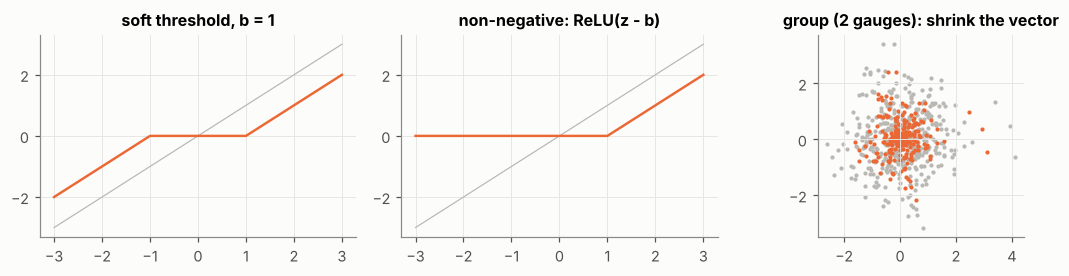

In [16]:
def prox_soft(z, b):  return torch.sign(z) * torch.relu(z.abs() - b)
def prox_relu(z, b):  return torch.relu(z - b)
def prox_group(z, b, dim=0):
    nrm = z.norm(dim=dim, keepdim=True).clamp_min(1e-12)
    return torch.relu(1 - b / nrm) * z
def prox_topk(z, s):
    out = torch.zeros_like(z); v, i = z.abs().topk(s, dim=-1)
    return out.scatter(-1, i, z.gather(-1, i))

zz = torch.linspace(-3, 3, 301)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
axes[0].plot(zz, zz, color="#b9b8b3", lw=0.8); axes[0].plot(zz, prox_soft(zz, 1.0), color=C["dunl"]); axes[0].set_title("soft threshold, b = 1")
axes[1].plot(zz, zz, color="#b9b8b3", lw=0.8); axes[1].plot(zz, prox_relu(zz, 1.0), color=C["dunl"]); axes[1].set_title("non-negative: ReLU(z - b)")
zg = torch.randn(2, 400); pg = prox_group(zg, 1.0)
axes[2].scatter(zg[0], zg[1], s=3, color="#b9b8b3"); axes[2].scatter(pg[0], pg[1], s=3, color=C["dunl"])
axes[2].set_title("group (2 gauges): shrink the vector"); axes[2].set_aspect("equal")
fig.tight_layout(); savefig(fig, "05_prox"); plt.show()

### 5.4 ISTA on one real trial, with a fixed kernel

Before learning anything, fix a reasonable kernel (gamma shape, peak about 6 h) and
solve only the code step on one window. Two settings:

* **known support**: codes allowed only in rainy hours; `λ` can be 0.
* **unknown support**: codes allowed anywhere; `λ` decides how many events.

A useful scale for `λ`: at `x = 0` the gradient is `-Hᵀ(w ⊙ (y - a))`, so for
non-negative codes `x = 0` is optimal exactly when
`λ ≥ λ_max = max_s [Hᵀ(w ⊙ (y - a))]_s`. We always set `λ = ratio · λ_max`.

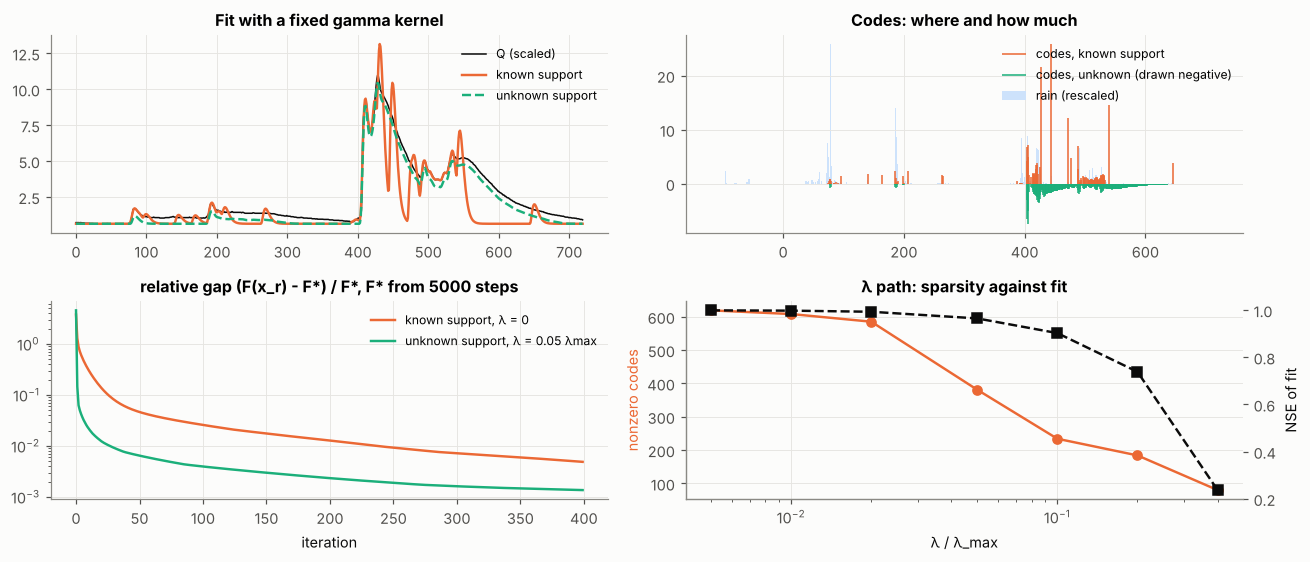

[INFO] relative gap after 100 / 400 steps: known 2.60e-02 / 4.86e-03, free 3.96e-03 / 1.36e-03


[INFO] single-trial ISTA: lambda_max=37.844, known-support nnz=104, free nnz=381; lambda path nnz=[619.0, 608.0, 585.0, 381.0, 234.0, 184.0, 80.0]


In [17]:
def lambda_max(y, w, h, a):
    return float(Ht_op(w * (y - a[:, None]), h).clamp_min(0).max())

lm = lambda_max(y1, w1, h_g, a1)
al = 0.9 / sigma2_fourier(h_g)
x_known, obj_known = ista(y1, w1, h_g, 0.0, al, 400, support=s1, a=a1)
x_free, obj_free = ista(y1, w1, h_g, 0.05 * lm, al, 400, support=None, a=a1)
# reference minima from long solves, so the gap is measured against (nearly) the true optimum
Fstar_known = ista(y1, w1, h_g, 0.0, al, 5000, support=s1, a=a1)[1].min()
Fstar_free = ista(y1, w1, h_g, 0.05 * lm, al, 5000, support=None, a=a1)[1].min()

ratios = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
nnz_path, fit_path = [], []
for r_ in ratios:
    xr_, _ = ista(y1, w1, h_g, r_ * lm, al, 400, a=a1, record=False)
    nnz_path.append(float((xr_ > 0).float().sum()))
    fit_path.append(float(1 - ((w1 * (H_op(xr_, h_g, T_TRIAL) + a1[:, None] - y1)) ** 2).sum()
                          / ((w1 * (y1 - y1.mean())) ** 2).sum()))

t_ax = np.arange(T_TRIAL); t_code = np.arange(-(L_DEFAULT - 1), T_TRIAL)
fig, axes = plt.subplots(2, 2, figsize=(12, 5.2))
ax = axes[0, 0]
ax.plot(t_ax, y1[0], color=C["flow"], lw=1, label="Q (scaled)")
ax.plot(t_ax, (H_op(x_known, h_g, T_TRIAL) + a1[:, None])[0], color=C["dunl"], label="known support")
ax.plot(t_ax, (H_op(x_free, h_g, T_TRIAL) + a1[:, None])[0], color=C["fir"], ls="--", label="unknown support")
ax.set_title("Fit with a fixed gamma kernel"); ax.legend(fontsize=8)
ax = axes[0, 1]
ax.bar(t_code, tr0["P"][0] / tr0["P"][0].max() * float(x_known.max()), width=1, color="#cde2fb", label="rain (rescaled)")
ax.vlines(t_code, 0, x_known[0, 0], color=C["dunl"], lw=1, label="codes, known support")
ax.vlines(t_code, 0, -x_free[0, 0], color=C["fir"], lw=1, label="codes, unknown (drawn negative)")
ax.set_title("Codes: where and how much"); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.semilogy((obj_known - Fstar_known) / abs(Fstar_known), color=C["dunl"], label="known support, λ = 0")
ax.semilogy((obj_free - Fstar_free) / abs(Fstar_free), color=C["fir"], label="unknown support, λ = 0.05 λmax")
ax.set_xlabel("iteration"); ax.set_title("relative gap (F(x_r) - F*) / F*, F* from 5000 steps"); ax.legend(fontsize=8)
ax = axes[1, 1]
ax.plot(ratios, nnz_path, "o-", color=C["dunl"]); ax.set_xscale("log")
ax.set_xlabel("λ / λ_max"); ax.set_ylabel("nonzero codes", color=C["dunl"])
ax2 = ax.twinx(); ax2.plot(ratios, fit_path, "s--", color=C["flow"]); ax2.set_ylabel("NSE of fit")
ax2.grid(False); ax.set_title("λ path: sparsity against fit")
fig.tight_layout(); savefig(fig, "05_ista_single_trial"); plt.show()
log.info(f"relative gap after 100 / 400 steps: known {(obj_known[99]-Fstar_known)/abs(Fstar_known):.2e} / "
         f"{(obj_known[-1]-Fstar_known)/abs(Fstar_known):.2e}, free {(obj_free[99]-Fstar_free)/abs(Fstar_free):.2e} / "
         f"{(obj_free[-1]-Fstar_free)/abs(Fstar_free):.2e}")
log.info(f"single-trial ISTA: lambda_max={lm:.3f}, known-support nnz={(x_known>0).sum().item()}, "
         f"free nnz={(x_free>0).sum().item()}; lambda path nnz={nnz_path}")

Two things to notice in the convergence panel (the numbers are in the log line).

* The **known-support** problem with `λ = 0` converges *slowly*. It is a non-negative
  least-squares problem over many neighbouring wet hours, and the columns of `H`
  for neighbouring hours are shifted copies of one smooth kernel, so they are nearly
  parallel: badly conditioned, as in 3c. A small `λ`, a coarser support (one code
  per storm instead of per hour), or the support-aware step from 5.2 all help.
* The **unknown-support** objective drops faster here because the `ℓ₁` term
  regularizes it. But the objective is not the whole story: finding *where* the
  events are is the hard part, and that is what the paper's advice (about 100 layers
  with known support, about 1000 without) is about.

### 5.5 The DUNL network

Unroll `R` ISTA steps into layers. All layers and the decoder share the same
kernels, so the only trained parameters are the kernels themselves:

```
x⁽⁰⁾ = 0,  a⁽⁰⁾ = 5th percentile of y
for r = 1..R:
    res   = w ⊙ (H x⁽ʳ⁻¹⁾ + a⁽ʳ⁻¹⁾ - y)
    x⁽ʳ⁾  = e ⊙ ReLU(x⁽ʳ⁻¹⁾ - α Hᵀ res - αλ)        # e = support mask (or all ones)
    a⁽ʳ⁾  = a⁽ʳ⁻¹⁾ - mean_t(w ⊙ (H x⁽ʳ⁾ + a⁽ʳ⁻¹⁾ - y))   # baseline update (paper eq. 7)
decoder: ŷ = H x⁽ᴿ⁾ + a⁽ᴿ⁾
loss:    ½ mean(w ⊙ (ŷ - y)²) + β Σ_k ‖D h_k‖²
```

After each Adam step: `h ← max(h, 0)` (optional) and `h_k ← h_k / ‖h_k‖₂`.

Options exposed in `DUNLConfig`, each tied to a modelling choice:

| option | meaning |
|---|---|
| `K`, `L` | number and length of kernels |
| `R` | encoder depth (ISTA steps) |
| `lam_ratio` | `λ / λ_max`, computed once at the start from the initial kernels |
| `support` | `"known"` (rainy hours) or `"free"` |
| `nonneg_codes`, `nonneg_kernels` | sign constraints |
| `infer_baseline` | update `a` inside the encoder, or keep the initial estimate |
| `grad_through_encoder` | `True`: backprop through all R layers (DUNL). `False`: treat codes as constants when updating `h` (classical alternating minimization) |
| `step_frac` | `α = step_frac / σ²` |
| `step_mode` | `"full"`: σ² of the whole `H` (paper). `"support"`: σ² of `H` restricted to each trial's support (5.2) |
| `lam_mode` | `"global"`: one `λ` for all trials. `"per_trial"`: `λ_j = ratio · λ_max,j`, which suits flow whose noise grows with its level |
| `accel` | `"none"`: ISTA layers (paper). `"fista"`: each layer extrapolates, `z = x_r + ((t_{r-1}-1)/t_r)(x_r - x_{r-1})`, same cost per layer, `O(1/k²)` instead of `O(1/k)` |
| `beta_smooth` | kernel roughness penalty |
| `init` | `"random"` (paper) or `"gamma"` |

In [18]:
@dataclass
class DUNLConfig:
    name: str = "dunl"
    K: int = 1
    L: int = 120
    R: int = 50
    lam_ratio: float = 0.0
    support: str = "known"            # "known" | "free"
    nonneg_codes: bool = True
    nonneg_kernels: bool = True
    infer_baseline: bool = True
    grad_through_encoder: bool = True
    step_frac: float = 0.9
    step_mode: str = "support"        # "full" | "support" (support only applies with known support)
    lam_mode: str = "global"          # "global" | "per_trial"
    accel: str = "none"               # "none" (ISTA, paper) | "fista" (Nesterov momentum, O(1/k²))
    beta_smooth: float = 1e-3
    lr: float = 0.02
    epochs: int = 150
    patience: int = 30
    init: str = "random"              # "random" | "gamma"
    seed: int = 0
    trace_every: int = 25             # epochs between encoder traces (0 = off)
    snapshot_every: int = 25          # epochs between kernel snapshots
    data: str = "real"                # tag only, for the summary table


class DUNL(nn.Module):
    def __init__(self, cfg: DUNLConfig):
        super().__init__()
        self.cfg = cfg
        g = torch.Generator().manual_seed(cfg.seed)
        if cfg.init == "gamma":
            peaks = np.linspace(4, 0.35 * cfg.L, cfg.K)
            h0 = np.stack([gamma_kernel(cfg.L, 3.0, p / 2.0) for p in peaks])
            h0 = torch.tensor(h0, dtype=DTYPE) + 0.01 * torch.rand(cfg.K, cfg.L, generator=g)
        else:
            h0 = torch.rand(cfg.K, cfg.L, generator=g, dtype=DTYPE)
            if not cfg.nonneg_kernels:
                h0 = h0 - 0.5
        self.h = nn.Parameter(h0 / h0.norm(dim=1, keepdim=True))
        self.lam = 0.0

    @torch.no_grad()
    def project(self):
        if self.cfg.nonneg_kernels:
            self.h.clamp_(min=0)
        self.h /= self.h.norm(dim=1, keepdim=True).clamp_min(1e-12)

    def alpha(self):
        """Scalar step from the full operator (logged every epoch)."""
        return self.cfg.step_frac / sigma2_fourier(self.h)

    def step_sizes(self, B, T, support):
        """Per-trial step, shape (B,1,1). Support-aware when allowed (Section 5.2)."""
        if self.cfg.step_mode == "support" and self.cfg.support == "known" and support is not None:
            with torch.no_grad():
                s2 = sigma2_power_masked(self.h, T, support)
            return (self.cfg.step_frac / s2)[:, None, None]
        return torch.full((B, 1, 1), self.alpha(), dtype=DTYPE)

    def lam_vector(self, y, w, a):
        """λ per trial, shape (B,1,1). 'global' uses self.lam; 'per_trial' rescales by each λ_max,j."""
        B = y.shape[0]
        if self.cfg.lam_ratio <= 0:
            return torch.zeros(B, 1, 1, dtype=DTYPE)
        if self.cfg.lam_mode == "per_trial":
            with torch.no_grad():
                lm = Ht_op(w * (y - a[:, None]), self.h.detach()).clamp_min(0).amax(dim=(1, 2))
            return (self.cfg.lam_ratio * lm)[:, None, None]
        return torch.full((B, 1, 1), self.lam, dtype=DTYPE)

    def encode(self, y, w, support=None, trace=False):
        cfg, h = self.cfg, self.h
        B, T = y.shape
        x = torch.zeros(B, cfg.K, T + cfg.L - 1, dtype=y.dtype)
        a = torch.quantile(y, 0.05, dim=1)
        e = support[:, None, :] if (cfg.support == "known" and support is not None) else None
        alpha = self.step_sizes(B, T, support if e is not None else None)
        lam = self.lam_vector(y, w, a)
        self._last_alpha = float(alpha.mean()); self._last_lam = float(lam.mean())
        tr = []
        zx, t_m = x, 1.0                     # FISTA extrapolation point and momentum scalar
        for r in range(cfg.R):
            res = w * (H_op(zx, h, T) + a[:, None] - y)
            z = zx - alpha * Ht_op(res, h)
            x_new = torch.relu(z - alpha * lam) if cfg.nonneg_codes else prox_soft(z, alpha * lam)
            if e is not None:
                x_new = x_new * e
            if cfg.accel == "fista":
                t_new = (1 + math.sqrt(1 + 4 * t_m * t_m)) / 2
                zx = x_new + ((t_m - 1) / t_new) * (x_new - x)
                t_m = t_new
            else:
                zx = x_new
            if trace:
                with torch.no_grad():
                    obj = 0.5 * float((res ** 2).sum()) + float((lam * x.abs()).sum())
                    rel = float((x_new - x).norm() / (x_new.norm() + 1e-12))
                    tr.append(dict(layer=r, objective=obj, rel_change=rel,
                                   nnz_frac=float((x_new != 0).float().mean()),
                                   res_norm=float(res.norm()), a_mean=float(a.mean())))
            x = x_new
            if cfg.infer_baseline:
                a = a - (w * (H_op(x, h, T) + a[:, None] - y)).sum(1) / w.sum(1).clamp_min(1)
        return x, a, tr

    def decode(self, x, a, T):
        return H_op(x, self.h, T) + a[:, None]

    def forward(self, y, w, support=None, trace=False):
        x, a, tr = self.encode(y, w, support, trace)
        if not self.cfg.grad_through_encoder:
            x, a = x.detach(), a.detach()
        return self.decode(x, a, y.shape[1]), x, a, tr

### 5.6 Run logging and health checks

Every training run writes its own folder. The checks below catch the usual silent
failures and write them to `warnings.txt` and the notebook log:

| check | what it catches |
|---|---|
| non-finite loss or kernels | divergence (step size, bad data) |
| encoder objective increases across layers | step too large |
| last-layer relative change > 1e-2 | encoder not converged: raise `R` |
| all codes zero | `λ` too large |
| kernel pair correlation > 0.95 | redundant kernels: `K` too large |
| kernel tail holds > 10% of its peak | `L` too short, or a slow component (baseflow) folded into the kernel |

In [19]:
class RunLogger:
    def __init__(self, cfg: DUNLConfig):
        self.dir = os.path.join(RUN_ROOT, cfg.name)
        os.makedirs(self.dir, exist_ok=True)
        self.log = log.getChild(cfg.name)
        self.warn_count = 0
        json.dump(asdict(cfg), open(os.path.join(self.dir, "config.json"), "w"), indent=2)
        self._ep = open(os.path.join(self.dir, "train_log.jsonl"), "w")
        self._tr = open(os.path.join(self.dir, "encoder_trace.jsonl"), "w")

    def epoch(self, rec):
        self._ep.write(json.dumps(rec) + "\n"); self._ep.flush()

    def trace(self, epoch, recs):
        for r in recs:
            self._tr.write(json.dumps(dict(epoch=epoch, **r)) + "\n")
        self._tr.flush()

    def snapshot(self, tag, h):
        np.save(os.path.join(self.dir, f"kernels_{tag}.npy"), h.detach().cpu().numpy())

    def warn(self, msg):
        self.warn_count += 1
        self.log.warning(msg)
        with open(os.path.join(self.dir, "warnings.txt"), "a") as f:
            f.write(msg + "\n")

    def finish(self, cfg, metrics):
        self._ep.close(); self._tr.close()
        json.dump(metrics, open(os.path.join(self.dir, "metrics.json"), "w"), indent=2)
        row = {**asdict(cfg), **metrics, "warnings": self.warn_count}
        # JSON lines: runs may log different metrics, so a fixed CSV header would break
        with open(os.path.join(RUN_ROOT, "summary.jsonl"), "a") as f:
            f.write(json.dumps(row, default=str) + "\n")


def load_summary():
    df = read_jsonl(os.path.join(RUN_ROOT, "summary.jsonl"))
    df.to_csv(os.path.join(RUN_ROOT, "summary.csv"), index=False)
    return df


def kernel_health(h, lg, tag=""):
    hn = h.detach().cpu().numpy()
    K = hn.shape[0]
    if K > 1:
        Cm = np.corrcoef(hn)
        iu = np.triu_indices(K, 1)
        if np.max(Cm[iu]) > 0.95:
            lg.warn(f"{tag} kernels nearly identical (max corr {np.max(Cm[iu]):.3f}); K may be too large")
    for k in range(K):
        pk = np.abs(hn[k]).max()
        if pk > 0 and np.abs(hn[k, -5:]).mean() > 0.10 * pk:
            lg.warn(f"{tag} kernel {k} tail still {np.abs(hn[k,-5:]).mean()/pk:.1%} of peak; L may be too short")


def nse(y, yh, w):
    """Nash-Sutcliffe efficiency (same as R² against the mean), masked."""
    m = (y * w).sum() / w.sum()
    return float(1 - ((w * (y - yh)) ** 2).sum() / ((w * (y - m)) ** 2).sum())


def train_dunl(cfg: DUNLConfig, data_tr, data_va, verbose=True):
    torch.manual_seed(cfg.seed); np.random.seed(cfg.seed)
    lg = RunLogger(cfg)
    model = DUNL(cfg)
    S_tr = data_tr["S"] if cfg.support == "known" else None
    S_va = data_va["S"] if cfg.support == "known" else None
    if cfg.lam_ratio > 0:
        with torch.no_grad():
            a0 = torch.quantile(data_tr["Y"], 0.05, dim=1)
            model.lam = cfg.lam_ratio * lambda_max(data_tr["Y"], data_tr["W"], model.h, a0)
    lg.log.debug(f"config: {asdict(cfg)}; lambda={model.lam:.4g}")
    opt = torch.optim.Adam([model.h], lr=cfg.lr)
    best = dict(val=np.inf, epoch=-1, h=model.h.detach().clone())
    t0, stale = time.time(), 0
    for ep in range(cfg.epochs):
        do_trace = cfg.trace_every > 0 and (ep % cfg.trace_every == 0 or ep == cfg.epochs - 1)
        yhat, x, a, tr = model(data_tr["Y"], data_tr["W"], S_tr, trace=do_trace)
        nll = 0.5 * ((data_tr["W"] * (yhat - data_tr["Y"])) ** 2).sum() / data_tr["W"].sum()
        smooth = cfg.beta_smooth * ((model.h[:, 1:] - model.h[:, :-1]) ** 2).sum()
        loss = nll + smooth
        if not torch.isfinite(loss):
            lg.warn(f"epoch {ep}: non-finite loss; stopping. alpha={model.alpha():.3g}")
            break
        opt.zero_grad(); loss.backward()
        gnorm = float(model.h.grad.norm())
        opt.step(); model.project()
        if not torch.isfinite(model.h).all():
            lg.warn(f"epoch {ep}: non-finite kernels; restoring best and stopping"); break
        with torch.no_grad():
            yv, _, _, _ = model(data_va["Y"], data_va["W"], S_va)
            vnll = float(0.5 * ((data_va["W"] * (yv - data_va["Y"])) ** 2).sum() / data_va["W"].sum())
        rec = dict(epoch=ep, loss=loss.item(), nll=nll.item(), smooth=smooth.item(), val_nll=vnll,
                   grad_norm=gnorm, alpha_full=model.alpha(), alpha_used=model._last_alpha,
                   sigma2_fourier=sigma2_fourier(model.h),
                   lam_used=model._last_lam, nnz_frac=float((x != 0).float().mean()),
                   code_mean=float(x.mean()), baseline_mean=float(a.mean()),
                   kernel_peak_lag=[int(i) for i in model.h.detach().argmax(1)], sec=time.time() - t0)
        lg.epoch(rec)
        if do_trace:
            lg.trace(ep, tr)
            objs = np.array([t["objective"] for t in tr])
            if cfg.accel != "fista" and len(objs) > 2 and np.any(np.diff(objs) > 1e-6 * abs(objs[0]) + 1e-9):
                lg.warn(f"epoch {ep}: encoder objective increased across layers (max rise "
                        f"{np.max(np.diff(objs)):.3g}); step may be too large")
            if tr[-1]["rel_change"] > 1e-2:
                lg.warn(f"epoch {ep}: encoder not converged (last-layer rel change {tr[-1]['rel_change']:.2e}); "
                        f"consider larger R")
        if rec["nnz_frac"] == 0:
            lg.warn(f"epoch {ep}: all codes are zero; lambda too large")
        if cfg.snapshot_every and ep % cfg.snapshot_every == 0:
            lg.snapshot(f"epoch{ep:04d}", model.h)
        if vnll < best["val"] - 1e-7:
            best = dict(val=vnll, epoch=ep, h=model.h.detach().clone()); stale = 0
        else:
            stale += 1
            if stale >= cfg.patience:
                lg.log.info(f"early stop at epoch {ep} (best {best['epoch']})"); break
    with torch.no_grad():
        model.h.copy_(best["h"])
    lg.snapshot("best", model.h)
    kernel_health(model.h, lg, cfg.name)
    metrics = dict(best_epoch=best["epoch"], best_val_nll=best["val"], epochs_run=ep + 1,
                   train_sec=round(time.time() - t0, 1), lam=model.lam)
    if verbose:
        log.info(f"[{cfg.name}] best val nll {best['val']:.5f} at epoch {best['epoch']} "
                 f"({metrics['train_sec']} s, {lg.warn_count} warnings)")
    return model, lg, metrics


@torch.no_grad()
def evaluate(model, data, R_eval=None):
    """Encode held-out trials with the learned kernels and score the reconstruction."""
    cfg = model.cfg
    if R_eval is not None:
        R0 = cfg.R; cfg.R = R_eval
    S = data["S"] if cfg.support == "known" else None
    yhat, x, a, _ = model(data["Y"], data["W"], S)
    if R_eval is not None:
        cfg.R = R0
    return dict(nse=nse(data["Y"], yhat, data["W"]), yhat=yhat, x=x, a=a)


def read_jsonl(path):
    return pd.DataFrame([json.loads(l) for l in open(path)])


def plot_diagnostics(run_dir, title=None, save_as=None):
    """Four panels from the run's logs: losses, step size, sparsity/gradient, encoder convergence."""
    ep = read_jsonl(os.path.join(run_dir, "train_log.jsonl"))
    tr_path = os.path.join(run_dir, "encoder_trace.jsonl")
    trc = read_jsonl(tr_path) if os.path.getsize(tr_path) > 0 else None
    fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
    axes[0].semilogy(ep.epoch, ep.nll, color=C["dunl"], label="train nll")
    axes[0].semilogy(ep.epoch, ep.val_nll, color=C["flow"], label="val nll"); axes[0].legend(fontsize=8)
    axes[0].set_title("loss")
    axes[1].plot(ep.epoch, ep.alpha_full, color="#b9b8b3", label="0.9/‖H‖²")
    axes[1].plot(ep.epoch, ep.alpha_used, color=C["rain"], label="used (mean)")
    axes[1].set_title("encoder step α"); axes[1].legend(fontsize=7)
    axes[2].plot(ep.epoch, ep.nnz_frac, color=C["fir"]); axes[2].set_title("code density (green), |∇h| (grey)")
    ax2 = axes[2].twinx(); ax2.plot(ep.epoch, ep.grad_norm, color="#b9b8b3", lw=1); ax2.grid(False)
    if trc is not None:
        for e, col in zip(sorted(trc.epoch.unique())[::max(1, len(trc.epoch.unique()) // 4)],
                          ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]):
            sub = trc[trc.epoch == e]
            axes[3].semilogy(sub.layer, sub.rel_change.clip(lower=1e-9), color=col, label=f"ep {e}")
        axes[3].legend(fontsize=7); axes[3].set_title("encoder: ‖x_r - x_{r-1}‖ / ‖x_r‖")
        axes[3].set_xlabel("layer")
    for a_ in axes[:3]:
        a_.set_xlabel("epoch")
    if title:
        fig.suptitle(title, y=1.04, fontweight="bold")
    fig.tight_layout()
    if save_as:
        savefig(fig, save_as)
    plt.show()


def kernel_match(h_est, h_true, max_shift=6):
    """Best cosine similarity over small shifts and kernel permutations (paper's metric).
    Returns per-true-kernel similarity and error sqrt(1 - sim^2)."""
    he, ht = np.atleast_2d(h_est), np.atleast_2d(h_true)
    def best_sim(a, b):
        s = []
        for d in range(-max_shift, max_shift + 1):
            a2 = np.roll(a, d)
            s.append(a2 @ b / (np.linalg.norm(a2) * np.linalg.norm(b) + 1e-12))
        return max(s)
    K = ht.shape[0]
    best, best_perm = -np.inf, None
    for perm in itertools.permutations(range(he.shape[0]), K):
        sims = [best_sim(he[perm[k]], ht[k]) for k in range(K)]
        if np.mean(sims) > best:
            best, best_perm = np.mean(sims), (perm, sims)
    perm, sims = best_perm
    return dict(perm=perm, sims=np.array(sims), err=np.sqrt(np.clip(1 - np.array(sims) ** 2, 0, None)))

## 6. Ground truth first: synthetic data with known kernels

Before trusting anything on real flow, build data where we know the answer. We
keep the **real rain** (so event timing and overlap are realistic) and generate
flow from two known kernels:

* **quick flow**: gamma kernel, peak about 6 h;
* **slow flow**: gamma kernel, peak about 20 h, long tail.

Both kernels fire at the same rainy hours (shared support), exactly like the
salience and value kernels at reward onset in the paper. Then add a constant
baseline, 3% Gaussian noise and the real missing-data mask.

### 6.1 An identifiability experiment

In our notes (Section 4.4), two kernels with the same support give, inside each
event window, a rank-2 factorization `R = [h_q h_s] C`. Any invertible `M` with
`[h_q h_s] M ≥ 0` and `M⁻¹ C ≥ 0` gives another exact solution. Non-negativity
rules out most `M` only if the amplitude pairs `(x_q, x_s)` of the events are
**spread out to the edges of the positive quadrant**: some events nearly all
quick, some nearly all slow (the "sufficiently scattered" condition of NMF theory).

Three datasets test exactly this:

| case | quick code | slow code | amplitude ratio `x_s / x_q` | theory |
|---|---|---|---|---|
| `coactive` | `rc(t)·P` | `0.3 · x_q` | constant | not identifiable (rank 1) |
| `correlated` | `rc(t)·P` | `0.15·P` | 0.23 to 3, a narrow cone | mixing ambiguity remains |
| `scattered` | `0.6·u·P` | `0.3·(1-u)·P` | 0 to ∞ | identifiable |

`rc(t)` grows with antecedent wetness (an antecedent precipitation index with a
5-day memory). In `scattered`, `u ∈ [0, 1]` is each storm's rank by peak rain
intensity: intense storms push water over the surface (quick), gentle ones let it
soak in (slow). That is a crude but physical reason for amplitudes to scatter.

**The decisive diagnostic.** If DUNL returns wrong kernels, is that bad
optimization or genuine non-identifiability? Plug the **true** kernels in and
compare the loss on test data. If the learned kernels fit as well as the truth, the
data cannot tell them apart.

One catch, found while building this notebook: the comparison must use a **deep,
accurate inner solve** (here 1000 FISTA steps). With the training encoder's 60 ISTA
steps, the true kernels look much *worse* than they are, because the inner problem
they create is badly conditioned and 60 steps do not solve it (the table logs both).

**Encoders.** The main runs use `accel="fista"` (Section 5.5). Two control runs use
the paper's plain ISTA layers on the `scattered` case, same depth, same seeds.

In [20]:
def make_synthetic(case="correlated", noise=0.03, seed=0):
    rng = np.random.default_rng(seed)
    p = P_all.values.astype(float)
    wet = (p > WET_THR).astype(float)
    api = signal.lfilter([1.0], [1.0, -np.exp(-1 / 120.0)], p)          # antecedent precipitation index
    rc = 0.05 + 0.6 * api / (api + 15.0)
    hq = gamma_kernel(L_DEFAULT, 3.0, 3.0)                              # unit-mass kernels
    hs = gamma_kernel(L_DEFAULT, 2.0, 20.0)
    if case == "coactive":
        xq = rc * p * wet; xs = 0.3 * xq
    elif case == "correlated":
        xq = rc * p * wet; xs = 0.15 * p * wet
    elif case == "scattered":
        u = np.full(len(p), 0.5)
        peak_int = np.array([p[s:e + 1].max() for s, e in zip(storms.i_start, storms.i_end)])
        ranks = stats.rankdata(peak_int) / len(peak_int)
        for (s, e), r_ in zip(zip(storms.i_start, storms.i_end), ranks):
            u[s:e + 1] = r_
        xq = 0.6 * u * p * wet; xs = 0.3 * (1 - u) * p * wet
    else:
        raise ValueError(case)
    q = signal.lfilter(hq, [1.0], xq) + signal.lfilter(hs, [1.0], xs) + 0.01
    q = q + noise * q.std() * rng.standard_normal(len(q))
    return q, np.stack([hq, hs]), dict(xq=xq, xs=xs, rc=rc)

def synthetic_subset(q_syn, name, L):
    sel = trials.split.values == name
    Ys = np.stack([q_syn[s:s + T_TRIAL] for s in starts[sel]]) / Q_SCALE
    d = subset(name, L)
    d["Y"] = to_t(Ys) * d["W"]                    # same missing pattern as the real data
    return d

@torch.no_grad()
def nll_with_kernels(h_np, cfg, data, R=1000, accel="fista"):
    """Data loss when a given set of kernels is plugged into a DEEP, accelerated solve.
    The deep solve matters: with a truncated encoder the true kernels can look worse
    than wrong ones simply because their inner problem converges more slowly."""
    c2 = DUNLConfig(**{**asdict(cfg), "R": R, "accel": accel})
    m_ = DUNL(c2)
    hh = torch.tensor(np.atleast_2d(h_np), dtype=DTYPE)
    m_.h.copy_(hh / hh.norm(dim=1, keepdim=True))
    yhat, _, _, _ = m_(data["Y"], data["W"], data["S"])
    return float(0.5 * ((data["W"] * (yhat - data["Y"])) ** 2).sum() / data["W"].sum())

SYN_CASES = ["coactive", "correlated", "scattered"]
# main experiment: FISTA encoder (accurate inner solve). Control: paper's ISTA on the scattered case.
SYN_RUNS = [(c, "fista", s_) for c in SYN_CASES for s_ in [0, 1]] + [("scattered", "none", s_) for s_ in [0, 1]]
syn_results, syn_rows = {}, []
syn_data = {}
for case in SYN_CASES:
    q_syn, h_true, comp = make_synthetic(case)
    syn_data[case] = (q_syn, h_true, comp, *(synthetic_subset(q_syn, s_, L_DEFAULT) for s_ in ["train", "val", "test"]))
for case, accel, seed in SYN_RUNS:
    q_syn, h_true, comp, dtr, dva, dte = syn_data[case]
    tag = "fista" if accel == "fista" else "ista"
    cfg = DUNLConfig(name=f"syn_{case}_K2_{tag}_s{seed}", K=2, L=L_DEFAULT, R=60, support="known", accel=accel,
                     epochs=400, patience=80, seed=seed, data=f"synthetic_{case}")
    model, lg, met = train_dunl(cfg, dtr, dva)
    ev = evaluate(model, dte)
    km = kernel_match(model.h.detach().numpy(), h_true)
    nll_learned = nll_with_kernels(model.h.detach().numpy(), cfg, dte)
    nll_true = nll_with_kernels(h_true, cfg, dte)
    nll_true_R60 = nll_with_kernels(h_true, cfg, dte, R=cfg.R, accel=accel)     # what training "sees"
    met.update(test_nse=ev["nse"], kernel_sim_quick=float(km["sims"][0]), kernel_sim_slow=float(km["sims"][1]),
               test_nll_learned_deep=nll_learned, test_nll_true_deep=nll_true, test_nll_true_at_R=nll_true_R60)
    lg.finish(cfg, met)
    syn_results[(case, tag, seed)] = dict(model=model, km=km, ev=ev, h_true=h_true, comp=comp, lg=lg, q=q_syn)
    syn_rows.append(dict(case=case, encoder=tag, seed=seed, test_nse=ev["nse"], cos_quick=km["sims"][0],
                         cos_slow=km["sims"][1], nll_learned_deep=nll_learned, nll_true_deep=nll_true,
                         nll_true_at_train_R=nll_true_R60))
    log.info(f"synthetic {case:10s} {tag:5s} seed {seed}: kernel cosine (quick, slow) = {km['sims'].round(3).tolist()}, "
             f"deep test nll learned {nll_learned:.5f} vs true {nll_true:.5f} (true at R={cfg.R}: {nll_true_R60:.5f})")

def verdict(r_):
    if min(r_["cos_quick"], r_["cos_slow"]) >= 0.9:
        return "recovered"
    if r_["nll_learned_deep"] <= 1.02 * r_["nll_true_deep"]:
        return "not identifiable: wrong kernels fit as well as the truth"
    return "optimization failure: truth fits better but was not found"

syn_table = pd.DataFrame(syn_rows)
syn_table["verdict"] = syn_table.apply(verdict, axis=1)
syn_table = syn_table.round(4)
syn_table.to_csv(os.path.join(RUN_ROOT, "synthetic_identifiability.csv"), index=False)
for _, r_ in syn_table.iterrows():
    log.info(f"identifiability verdict {r_.case:10s} {r_.encoder:5s} seed {r_.seed}: {r_.verdict}")
syn_table

/tmp/ipykernel_2956/940831963.py:98: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  code_mean=float(x.mean()), baseline_mean=float(a.mean()),


[INFO] early stop at epoch 230 (best 150)


[INFO] [syn_coactive_K2_fista_s0] best val nll 0.00212 at epoch 150 (51.8 s, 0 warnings)


[INFO] synthetic coactive   fista seed 0: kernel cosine (quick, slow) = [0.983, 0.761], deep test nll learned 0.00161 vs true 0.00177 (true at R=60: 0.00260)


[INFO] [syn_coactive_K2_fista_s1] best val nll 0.00204 at epoch 392 (89.2 s, 0 warnings)


[INFO] synthetic coactive   fista seed 1: kernel cosine (quick, slow) = [0.987, 0.684], deep test nll learned 0.00160 vs true 0.00177 (true at R=60: 0.00260)


... (19 outputs left out)

[INFO] identifiability verdict scattered  fista seed 1: recovered


[INFO] identifiability verdict scattered  ista  seed 0: optimization failure: truth fits better but was not found


[INFO] identifiability verdict scattered  ista  seed 1: optimization failure: truth fits better but was not found


,case,encoder,seed,test_nse,cos_quick,cos_slow,nll_learned_deep,nll_true_deep,nll_true_at_train_R,verdict
0,coactive,fista,0,0.9994,0.9829,0.7608,0.0016,0.0018,0.0026,not identifiable: wrong kernels fit as well as...
1,coactive,fista,1,0.9994,0.9868,0.6838,0.0016,0.0018,0.0026,not identifiable: wrong kernels fit as well as...
2,correlated,fista,0,0.9994,0.9803,0.7629,0.0018,0.0018,0.0027,not identifiable: wrong kernels fit as well as...
3,correlated,fista,1,0.9994,0.9842,0.7419,0.0018,0.0018,0.0027,not identifiable: wrong kernels fit as well as...
4,scattered,fista,0,0.9992,0.9985,0.9434,0.0023,0.0023,0.0032,recovered
5,scattered,fista,1,0.9992,0.9987,0.9024,0.0025,0.0023,0.0032,recovered
6,scattered,ista,0,0.9977,0.9714,0.6684,0.0053,0.0023,0.0163,optimization failure: truth fits better but wa...
7,scattered,ista,1,0.9976,0.9542,0.6695,0.0057,0.0023,0.0163,optimization failure: truth fits better but wa...


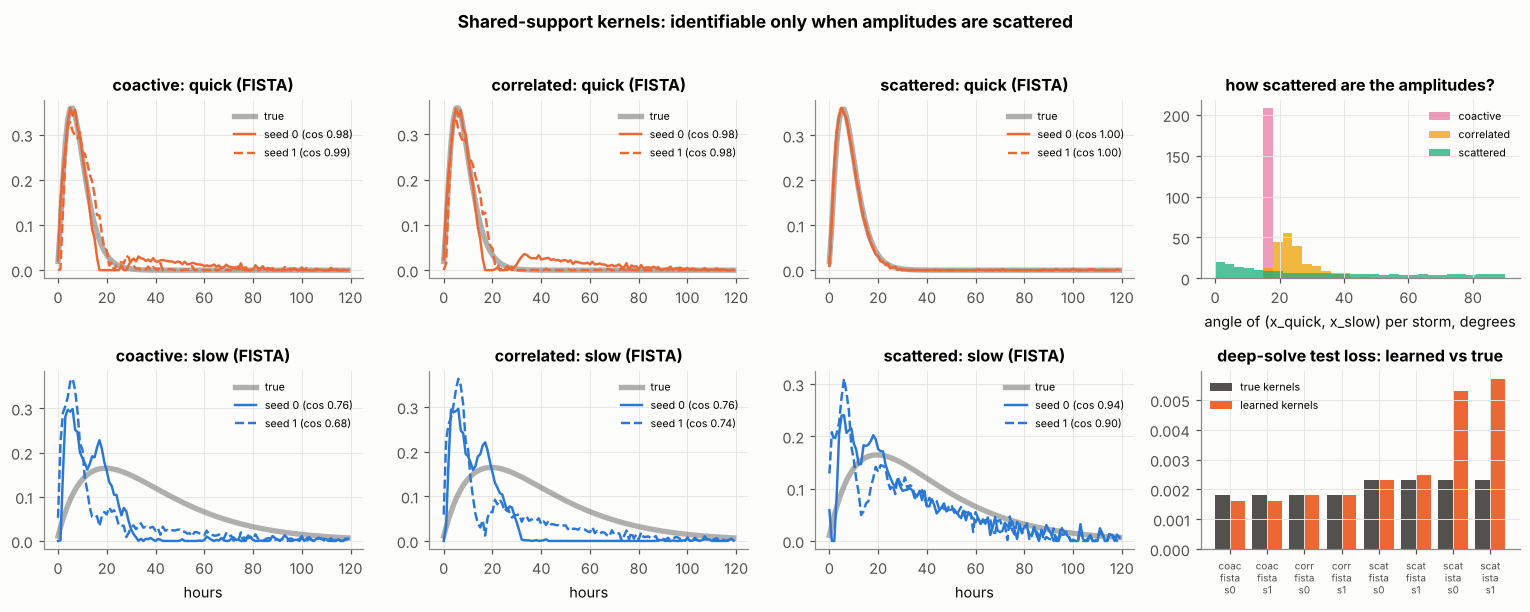

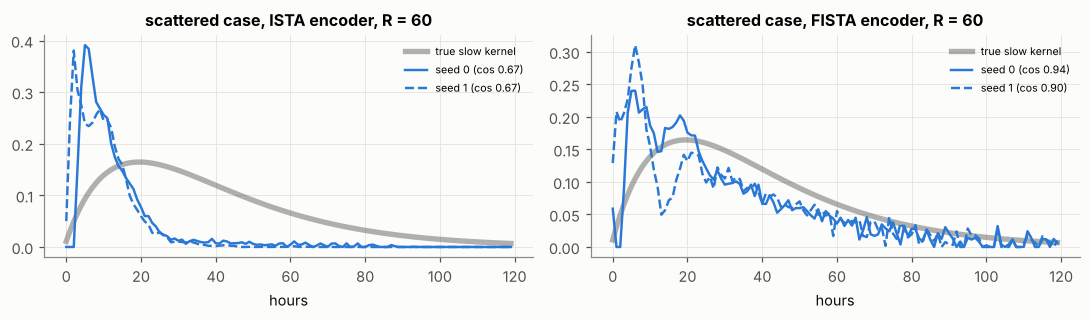

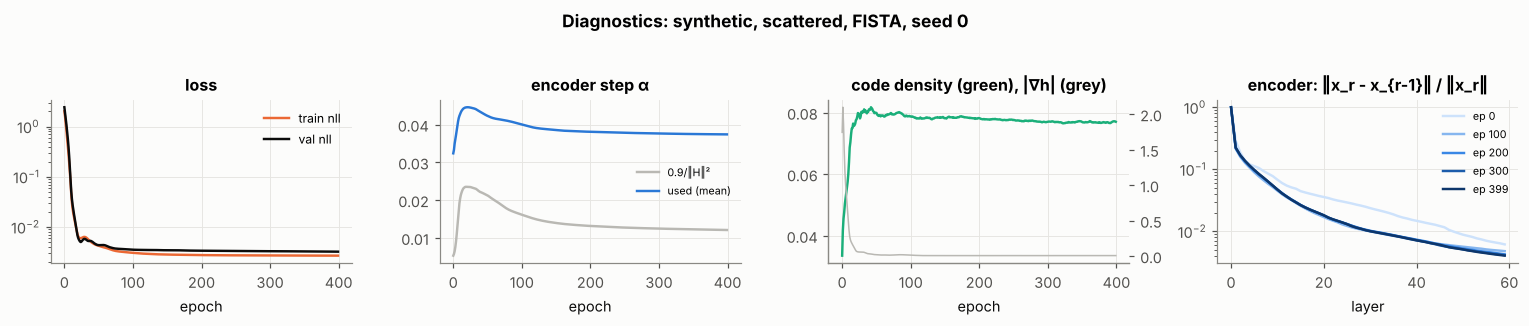

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.4))
lag = np.arange(L_DEFAULT)
for col, case in enumerate(SYN_CASES):
    for j, name in enumerate(["quick", "slow"]):
        ax = axes[j, col]
        ht = syn_results[(case, "fista", 0)]["h_true"][j]
        ax.plot(lag, ht / np.linalg.norm(ht), color=C["truth"], lw=3.5, alpha=0.45, label="true")
        for seed, ls in [(0, "-"), (1, "--")]:
            r = syn_results[(case, "fista", seed)]
            he = r["model"].h.detach().numpy()[r["km"]["perm"][j]]
            ax.plot(lag, he, color=C["dunl"] if j == 0 else C["rain"], ls=ls,
                    label=f"seed {seed} (cos {r['km']['sims'][j]:.2f})")
        ax.set_title(f"{case}: {name} (FISTA)"); ax.legend(fontsize=7)
        if j == 1: ax.set_xlabel("hours")
ax = axes[0, 3]
for case, col in zip(SYN_CASES, [C["eta"], C["gamma"], C["fir"]]):
    cp = syn_results[(case, "fista", 0)]["comp"]
    mq = np.array([cp["xq"][s_:e_ + 1].sum() for s_, e_ in zip(storms.i_start, storms.i_end)])
    ms = np.array([cp["xs"][s_:e_ + 1].sum() for s_, e_ in zip(storms.i_start, storms.i_end)])
    ang = np.degrees(np.arctan2(ms, mq + 1e-12))
    ax.hist(ang, bins=np.linspace(0, 90, 31), color=col, alpha=0.75, label=case)
ax.set_xlabel("angle of (x_quick, x_slow) per storm, degrees"); ax.set_title("how scattered are the amplitudes?")
ax.legend(fontsize=7)
ax = axes[1, 3]
xs_ = np.arange(len(syn_table))
ax.bar(xs_ - 0.2, syn_table.nll_true_deep, width=0.4, color=C["truth"], label="true kernels")
ax.bar(xs_ + 0.2, syn_table.nll_learned_deep, width=0.4, color=C["dunl"], label="learned kernels")
ax.set_xticks(xs_)
ax.set_xticklabels([f"{c[:4]}\n{e}\ns{s_}" for c, e, s_ in zip(syn_table.case, syn_table.encoder, syn_table.seed)], fontsize=6.5)
ax.set_title("deep-solve test loss: learned vs true"); ax.legend(fontsize=7)
fig.suptitle("Shared-support kernels: identifiable only when amplitudes are scattered", y=1.02, fontweight="bold")
fig.tight_layout(); savefig(fig, "06_synthetic_identifiability"); plt.show()

# the truncation effect: same data, same seeds, ISTA vs FISTA encoder (R = 60)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, tag in zip(axes, ["ista", "fista"]):
    ht = syn_results[("scattered", tag, 0)]["h_true"][1]
    ax.plot(lag, ht / np.linalg.norm(ht), color=C["truth"], lw=3.5, alpha=0.45, label="true slow kernel")
    for seed, ls in [(0, "-"), (1, "--")]:
        r = syn_results[("scattered", tag, seed)]
        ax.plot(lag, r["model"].h.detach().numpy()[r["km"]["perm"][1]], color=C["rain"], ls=ls,
                label=f"seed {seed} (cos {r['km']['sims'][1]:.2f})")
    ax.set_title(f"scattered case, {tag.upper()} encoder, R = 60"); ax.legend(fontsize=7); ax.set_xlabel("hours")
fig.tight_layout(); savefig(fig, "06_ista_vs_fista"); plt.show()

plot_diagnostics(syn_results[("scattered", "fista", 0)]["lg"].dir, "Diagnostics: synthetic, scattered, FISTA, seed 0",
                 "06_synthetic_diagnostics")

How to read this. The deep-solve loss comparison sorts every failure into one of
two kinds:

* **Not identifiable**: the learned kernels miss the truth, yet they fit held-out
  data as well as (or better than) the true kernels. The data cannot tell the two
  answers apart, and no amount of training fixes it. This is what theory predicts
  for `coactive`. A good fit says nothing about whether the parts are real.
* **Optimization failure**: the learned kernels miss the truth *and* the truth fits
  clearly better. A better solution exists; training did not reach it.

**The truncation effect** (second figure). On the `scattered` data, the paper's ISTA
encoder with `R = 60` does not recover the slow kernel, while FISTA with the same
depth does. The reason is in the logged numbers: through a 60-step ISTA encoder
the true kernels score *badly*, because 60 steps cannot solve the ill-conditioned
inner problem they create. Training through a truncated encoder therefore pulls the
kernels toward ones whose inner problem converges fast, not toward the true ones.
This is open question A4 (what the unrolled gradient optimizes) made concrete, and
an accelerated inner solver is a cheap, effective fix.

Look also at *how* the wrong slow kernels are wrong: in the non-identifiable cases
they borrow the early, fast part of the response (a bump in the first 10 h) that
belongs to the quick kernel. That is the mixing `[h_q h_s] M` from our notes, seen
directly: the slow kernel becomes a combination of both.

Which cases land where (see the table and the log) is the experiment's result. The
histogram shows the mechanism: what matters is how far the amplitude pairs spread
across the quadrant, not merely whether they vary.

For the dopamine data the same question decides whether "salience" and "value" are
two signals or one signal cut in two. Reward sizes there span two orders of
magnitude, which may be what makes their split work. This is a precise, testable
version of open question A1, and this loss comparison is the tool to test it.

### 6.2 Do the amplitudes carry the right information?

In the paper, the key result is that DUNL codes track reward size better than a
fixed window. The analogue here: per storm, does the DUNL estimate of the runoff
coefficient track the true one better than a window estimate? We use the
`correlated` case, where the true coefficient depends on wetness, and the **total**
effective rain (both kernels, mass gauge). The total is identifiable even when the
split between kernels is not, because it equals the volume under the hydrograph.

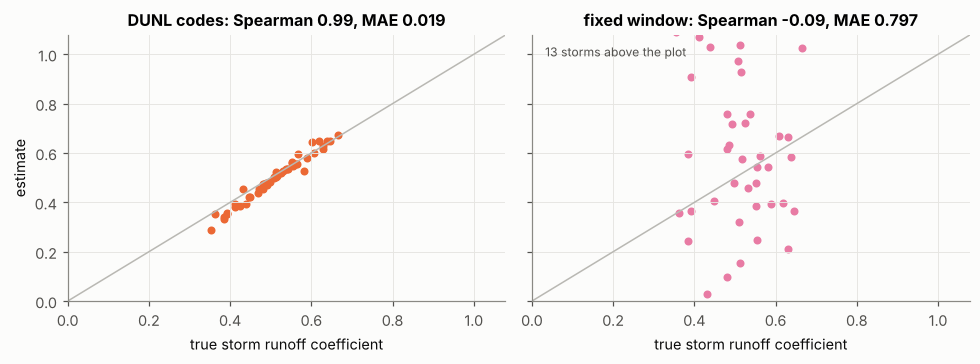

[INFO] synthetic test storms: n=51, vs truth: DUNL Spearman 0.987 MAE 0.019; window Spearman -0.092 MAE 0.797


In [22]:
def storm_code_mass(x_codes, data, model_h, storms_df, L):
    """Sum mass-gauge codes (effective rain, mm) over each storm's hours, per trial."""
    hsum = model_h.detach().numpy().sum(1)                  # mass gauge: h/Σh, x·Σh
    out = {}
    for row_i, ti in enumerate(data["idx"]):
        s0 = starts[ti] - (L - 1)                           # absolute index of code position 0
        xm = (x_codes[row_i].numpy() * hsum[:, None]) * Q_SCALE   # (K, T+L-1), mm per hour
        for _, st in storms_df.iterrows():
            a0, a1 = st.i_start - s0, st.i_end - s0 + 1
            if a0 >= L - 1 and a1 <= xm.shape[1]:            # storm inside the window proper
                out[st.i_start] = xm[:, a0:a1].sum(1)
    return out

r = syn_results[("correlated", "fista", 0)]
q_syn, comp = r["q"], r["comp"]
dte = synthetic_subset(q_syn, "test", L_DEFAULT)
ev = evaluate(r["model"], dte)
cm = storm_code_mass(ev["x"], dte, r["model"].h, storms, L_DEFAULT)
rows = []
for _, st in storms.iterrows():
    if st.i_start in cm:
        true_rc = (comp["xq"] + comp["xs"])[st.i_start:st.i_end + 1].sum() / st.depth_mm
        rows.append(dict(i_start=st.i_start, depth=st.depth_mm, rc_true=true_rc,
                         rc_dunl=cm[st.i_start].sum() / st.depth_mm,
                         rc_window=window_runoff_ratio(q_syn, st.i_start, st.depth_mm, L_DEFAULT)))
syn_rc = pd.DataFrame(rows).dropna()
rho_d = stats.spearmanr(syn_rc.rc_true, syn_rc.rc_dunl).statistic
rho_w = stats.spearmanr(syn_rc.rc_true, syn_rc.rc_window).statistic
mae_d = np.mean(np.abs(syn_rc.rc_dunl - syn_rc.rc_true)); mae_w = np.mean(np.abs(syn_rc.rc_window - syn_rc.rc_true))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True, sharey=True)
lim = [0, float(max(syn_rc.rc_true.max(), syn_rc.rc_dunl.max()) * 1.6)]
for ax, col_, c_, nm, rho_, mae_ in [(axes[0], "rc_dunl", C["dunl"], "DUNL codes", rho_d, mae_d),
                                     (axes[1], "rc_window", C["eta"], "fixed window", rho_w, mae_w)]:
    ax.plot(lim, lim, color="#b9b8b3", lw=1)
    ax.scatter(syn_rc.rc_true, syn_rc[col_], color=c_, s=18)
    ax.set_title(f"{nm}: Spearman {rho_:.2f}, MAE {mae_:.3f}")
    ax.set_xlabel("true storm runoff coefficient"); ax.set_xlim(lim); ax.set_ylim(lim)
    n_off = int((syn_rc[col_] > lim[1]).sum())
    if n_off:
        ax.text(0.03, 0.92, f"{n_off} storms above the plot", transform=ax.transAxes, fontsize=8, color="#52514e")
axes[0].set_ylabel("estimate")
fig.tight_layout(); savefig(fig, "06_synthetic_rc"); plt.show()
log.info(f"synthetic test storms: n={len(syn_rc)}, vs truth: DUNL Spearman {rho_d:.3f} MAE {mae_d:.3f}; "
         f"window Spearman {rho_w:.3f} MAE {mae_w:.3f}")

## 7. DUNL on real flow

### 7.1 Known support, one kernel

Codes are allowed only in rainy hours. The learned kernel is the basin's unit
hydrograph (up to the gauge: we report it in the *mass gauge* `h/Σh`, so the code
times `Σh` is effective rain in mm).

[INFO] early stop at epoch 45 (best 15)


[INFO] [real_known_K1] best val nll 0.00396 at epoch 15 (8.6 s, 0 warnings)


[INFO] real known-support K=1: test NSE (reconstruction) 0.9640


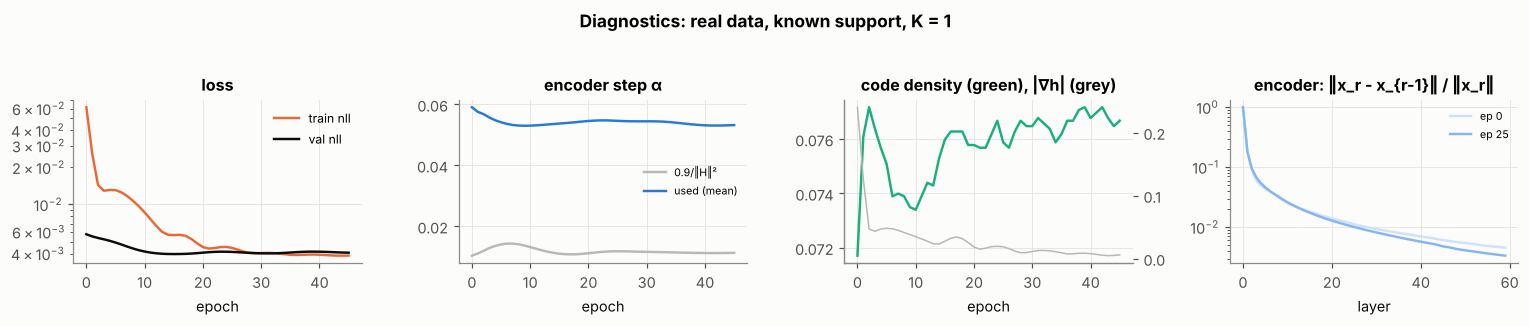

In [23]:
D = {s: subset(s, L_DEFAULT) for s in ["train", "val", "test"]}
cfg_k1 = DUNLConfig(name="real_known_K1", K=1, L=L_DEFAULT, R=60, support="known", epochs=200)
m_k1, lg_k1, met = train_dunl(cfg_k1, D["train"], D["val"])
ev_k1 = evaluate(m_k1, D["test"])
met.update(test_nse=ev_k1["nse"]); lg_k1.finish(cfg_k1, met)
log.info(f"real known-support K=1: test NSE (reconstruction) {ev_k1['nse']:.4f}")
plot_diagnostics(lg_k1.dir, "Diagnostics: real data, known support, K = 1", "07_k1_diagnostics")

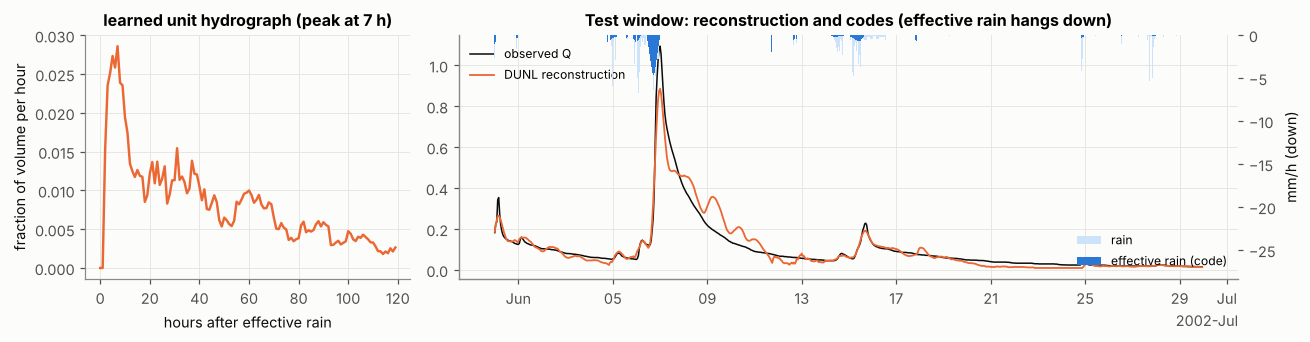

In [24]:
h1 = m_k1.h.detach().numpy()[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[1, 2.4]))
axes[0].plot(np.arange(L_DEFAULT), h1 / h1.sum(), color=C["dunl"])
axes[0].set_title(f"learned unit hydrograph (peak at {h1.argmax()} h)")
axes[0].set_xlabel("hours after effective rain"); axes[0].set_ylabel("fraction of volume per hour")
j = 2
ax = axes[1]
t_abs = Q_all.index[starts[D["test"]["idx"][j]]:starts[D["test"]["idx"][j]] + T_TRIAL]
ax.plot(t_abs, D["test"]["Y"][j] * Q_SCALE, color=C["flow"], lw=1, label="observed Q")
ax.plot(t_abs, ev_k1["yhat"][j] * Q_SCALE, color=C["dunl"], lw=1.2, label="DUNL reconstruction")
ax2 = ax.twinx(); ax2.grid(False)
xm = ev_k1["x"][j, 0, L_DEFAULT - 1:].numpy() * h1.sum() * Q_SCALE
ax2.bar(t_abs, -D["test"]["P"][j, L_DEFAULT - 1:].numpy(), width=1 / 24, color="#cde2fb", label="rain")
ax2.bar(t_abs, -xm, width=1 / 24, color=C["rain"], label="effective rain (code)")
ax2.set_ylim(-3 * max(1e-3, float(D["test"]["P"][j].max())), 0); ax2.set_ylabel("mm/h (down)")
ax.legend(loc="upper left", fontsize=8); ax2.legend(loc="lower right", fontsize=8)
ax.set_title("Test window: reconstruction and codes (effective rain hangs down)")
fig.tight_layout(); savefig(fig, "07_k1_kernel_and_trial"); plt.show()

### 7.2 What the codes say about the catchment

The analogue of the paper's Figure 2F: per storm, runoff coefficient from DUNL
codes vs from a fixed window, each against antecedent wetness. If DUNL removes the
contamination from neighbouring storms, its coefficient should relate more clearly
to wetness. (With real data there is no ground truth, so this is evidence, not
proof; the synthetic test above is the proof.)

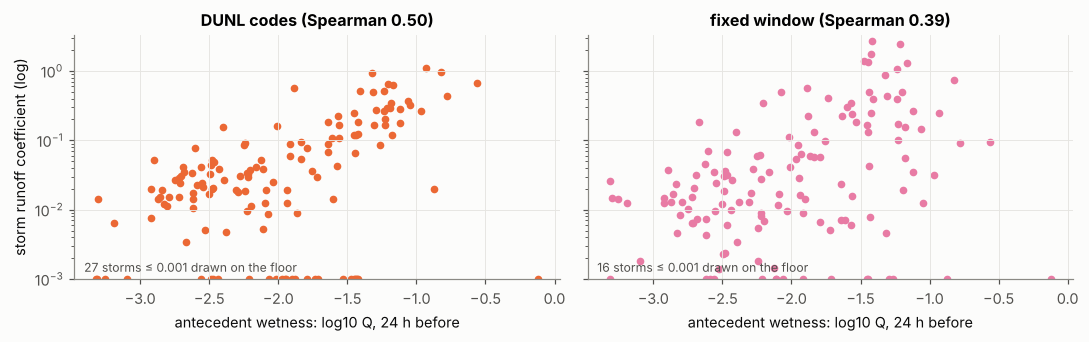

[INFO] real storms n=140: Spearman(wetness, rc) DUNL 0.503 vs window 0.393


In [25]:
def storm_rc_table(model, data_names=("train", "val", "test"), L=L_DEFAULT, k=0):
    rows = []
    for nm in data_names:
        ev_ = evaluate(model, D[nm])
        cm_ = storm_code_mass(ev_["x"], D[nm], model.h, storms, L)
        for _, st in storms.iterrows():
            if st.i_start in cm_:
                rows.append(dict(split=nm, i_start=st.i_start, depth=st.depth_mm, log_q_pre=st.log_q_pre,
                                 month=st.start.month, rc_dunl=cm_[st.i_start][k] / st.depth_mm,
                                 rc_window=window_runoff_ratio(q_np, st.i_start, st.depth_mm, L)))
    return pd.DataFrame(rows).dropna()

rc_real = storm_rc_table(m_k1)
rc_real.to_csv(os.path.join(RUN_ROOT, "storm_runoff_coefficients.csv"), index=False)
rd = stats.spearmanr(rc_real.log_q_pre, rc_real.rc_dunl).statistic
rw = stats.spearmanr(rc_real.log_q_pre, rc_real.rc_window).statistic
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].scatter(rc_real.log_q_pre, rc_real.rc_dunl.clip(lower=1e-3), color=C["dunl"], s=16)
axes[0].set_title(f"DUNL codes (Spearman {rd:.2f})")
axes[1].scatter(rc_real.log_q_pre, rc_real.rc_window.clip(lower=1e-3), color=C["eta"], s=16)
axes[1].set_title(f"fixed window (Spearman {rw:.2f})")
ylo = 1e-3
for ax in axes:
    ax.set_xlabel("antecedent wetness: log10 Q, 24 h before"); ax.set_yscale("log")
    ax.set_ylim(ylo, max(3.0, float(rc_real[["rc_dunl", "rc_window"]].max().max()) * 1.2))
for ax, col_ in zip(axes, ["rc_dunl", "rc_window"]):
    n0 = int((rc_real[col_] < ylo).sum())
    if n0:
        ax.text(0.02, 0.03, f"{n0} storms ≤ {ylo} drawn on the floor", transform=ax.transAxes, fontsize=8, color="#52514e")
axes[0].set_ylabel("storm runoff coefficient (log)")
fig.tight_layout(); savefig(fig, "07_rc_vs_wetness"); plt.show()
log.info(f"real storms n={len(rc_real)}: Spearman(wetness, rc) DUNL {rd:.3f} vs window {rw:.3f}")

### 7.3 Two kernels: quick and slow flow

Hydrologists split a hydrograph into quick flow and baseflow by hand-tuned filters.
With `K = 2` and shared support, DUNL tries to learn that split. From the synthetic
test we know the split is identifiable only if the two amplitudes vary differently
across storms. We train with 3 seeds and compare, using the FISTA encoder since
Section 6 showed it matters for shared-support kernels.

[INFO] early stop at epoch 211 (best 151)


[WARNING] real_known_K2_s0 kernel 0 tail still 10.9% of peak; L may be too short


[INFO] [real_known_K2_s0] best val nll 0.00258 at epoch 151 (46.6 s, 1 warnings)


[INFO] K=2 seed 0: test NSE 0.9954, peak lags [4, 20]


[WARNING] epoch 0: encoder not converged (last-layer rel change 1.04e-02); consider larger R


[INFO] early stop at epoch 186 (best 126)


... (3 outputs left out)

[WARNING] epoch 0: encoder not converged (last-layer rel change 1.06e-02); consider larger R


[WARNING] real_known_K2_s2 kernel 0 tail still 59.2% of peak; L may be too short


[INFO] [real_known_K2_s2] best val nll 0.00245 at epoch 299 (66.4 s, 2 warnings)


[INFO] K=2 seed 2: test NSE 0.9971, peak lags [7, 2]


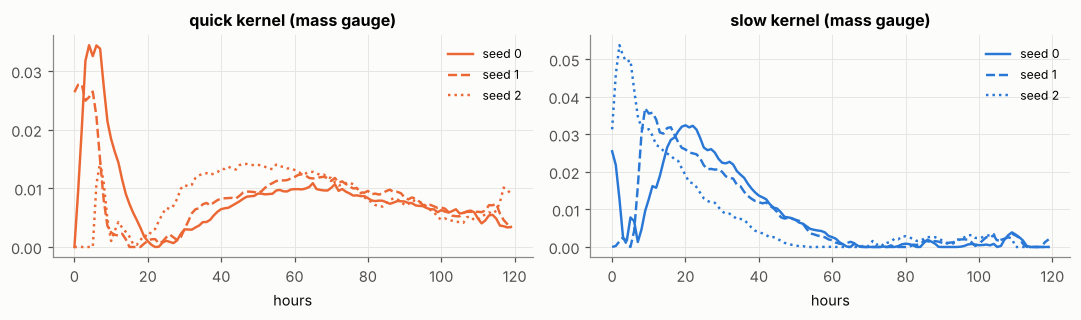

[INFO] K=2 cross-seed kernel cosine vs seed 0: [[1.0, 1.0], [0.8629999756813049, 0.8849999904632568], [0.6859999895095825, 0.6439999938011169]]


In [26]:
k2_models = []
for seed in range(3):
    cfg = DUNLConfig(name=f"real_known_K2_s{seed}", K=2, L=L_DEFAULT, R=60, support="known", epochs=300,
                     patience=60, seed=seed, accel="fista")
    mdl, lg, met = train_dunl(cfg, D["train"], D["val"])
    evk = evaluate(mdl, D["test"]); met.update(test_nse=evk["nse"]); lg.finish(cfg, met)
    k2_models.append((mdl, evk))
    log.info(f"K=2 seed {seed}: test NSE {evk['nse']:.4f}, peak lags {mdl.h.argmax(1).tolist()}")

ref = k2_models[0][0].h.detach().numpy()
ref = ref[np.argsort(ref.argmax(1))]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
stab = []
for seed, (mdl, evk) in enumerate(k2_models):
    km = kernel_match(mdl.h.detach().numpy(), ref, max_shift=0)
    stab.append(km["sims"])
    for j in range(2):
        hj = mdl.h.detach().numpy()[km["perm"][j]]
        axes[j].plot(hj / hj.sum(), ls=["-", "--", ":"][seed], color=C["dunl"] if j == 0 else C["rain"],
                     label=f"seed {seed}")
axes[0].set_title("quick kernel (mass gauge)"); axes[1].set_title("slow kernel (mass gauge)")
for ax in axes:
    ax.legend(fontsize=8); ax.set_xlabel("hours")
fig.tight_layout(); savefig(fig, "07_k2_kernels"); plt.show()
log.info(f"K=2 cross-seed kernel cosine vs seed 0: {np.array(stab).round(3).tolist()}")

Reading the K = 2 result. If the seeds agree (cosine near 1 in the log line), the
split is at least stable; if one seed lands elsewhere, the loss surface has more
than one good answer, the same pattern as the `correlated` and `coactive`
synthetic cases. Stability across seeds is necessary for a physical reading of
"quick" and "slow" flow, but not sufficient: Section 6 showed wrong kernels can be
both stable and well fitting. On real data there is no truth to plug in, so the
honest statement is that the split is a hypothesis, not a measurement.

### 7.4 Unknown support: find the events from flow alone

Now hide the rain. DUNL must find **when** effective rain happened, from `Q` only.
This is blind deconvolution. Four things to watch:

* **λ per trial.** Flow noise grows with flow. One global `λ` (set by the big
  spring windows) wipes out every code in a dry August window. We use
  `lam_mode="per_trial"`: `λ_j = ratio · λ_max,j`.
* **The shift gauge.** `(S_τ h) ∗ (S_{-τ} x) = h ∗ x`, so the learned kernel can
  start late (leading zeros) and the codes then sit *earlier* than the rain, or the
  other way round. We estimate this offset on the training years and correct for
  it before scoring the test year. This is the paper's tolerance-window issue made
  explicit.
* **Depth.** Unknown support needs more ISTA steps (Section 5.4), so `R = 150`.
* **What counts as an event.** In August and September the runoff ratio is about
  0.03 (Section 2), so many storms leave no trace in the flow. No method can find
  those from `Q`. We score against **responsive storms** (window runoff ≥ 0.3 mm)
  and report all storms too.

Events from codes: local maxima of the code series (summed over kernels), at least
6 h apart, above a height threshold. Sweeping that threshold gives a curve, the same
way a peak-finder's prominence does.

In [27]:
def match_events(det_abs, true_abs, tol=6):
    det_abs, true_abs = np.sort(det_abs), np.sort(true_abs)
    used, hits = set(), 0
    for t in true_abs:
        cand = [i for i, d in enumerate(det_abs) if abs(d - t) <= tol and i not in used]
        if cand:
            used.add(min(cand, key=lambda i: abs(det_abs[i] - t))); hits += 1
    prec = len(used) / max(len(det_abs), 1); rec = hits / max(len(true_abs), 1)
    return dict(precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-12),
                n_det=len(det_abs), n_true=len(true_abs))

storms["runoff_window_mm"] = [window_runoff_ratio(q_np, s, d, L_DEFAULT) * d
                              for s, d in zip(storms.i_start, storms.depth_mm)]
storms["responsive"] = storms.runoff_window_mm >= 0.3
log.info(f"responsive storms (window runoff >= 0.3 mm): {storms.responsive.sum()} of {len(storms)}")

def storms_in(data, responsive_only=True):
    out = []
    sel = storms[storms.responsive] if responsive_only else storms
    for ti in data["idx"]:
        s0, s1 = starts[ti], starts[ti] + T_TRIAL
        out += [s for s in sel.i_start if s0 <= s < s1]
    return np.array(out)

def code_peaks_abs(x, data, L, height):
    """Local maxima of the summed code series, >= 6 h apart, above `height` -> absolute hour index."""
    out = []
    for row_i, ti in enumerate(data["idx"]):
        v = x[row_i].sum(0).numpy()
        pk, _ = signal.find_peaks(np.r_[0, v, 0], height=height, distance=STORM_GAP)
        absn = starts[ti] - (L - 1) + (pk - 1)
        out += [a for a in absn if starts[ti] - 24 <= a < starts[ti] + T_TRIAL]
    return np.array(out)

def estimate_offset(det, true, max_off=24):
    """Median signed distance from each true onset to the nearest detection (the shift gauge)."""
    d = [det[np.argmin(np.abs(det - t))] - t for t in true if len(det) and np.min(np.abs(det - t)) <= max_off]
    return int(np.median(d)) if d else 0

def code_detection_curve(ev_tr, ev_te, d_tr, d_te, L, n=20):
    """Sweep the code height threshold; offset calibrated on training years at each threshold."""
    pos = ev_tr["x"].sum(1).flatten().numpy(); pos = pos[pos > 0]
    if len(pos) == 0:
        return pd.DataFrame()
    rows = []
    for q_ in np.linspace(0.0, 0.98, n):
        hgt = float(np.quantile(pos, q_))
        off = estimate_offset(code_peaks_abs(ev_tr["x"], d_tr, L, hgt), storms_in(d_tr))
        sc = match_events(code_peaks_abs(ev_te["x"], d_te, L, hgt) - off, storms_in(d_te))
        sc_all = match_events(code_peaks_abs(ev_te["x"], d_te, L, hgt) - off, storms_in(d_te, False))
        rows.append(dict(quantile=q_, height=hgt, offset=off, **sc, recall_all_storms=sc_all["recall"]))
    return pd.DataFrame(rows)

R_FREE = 150
D_full_tr = {k: torch.cat([D["train"][k], D["val"][k]]) if torch.is_tensor(D["train"][k]) else
             np.r_[D["train"][k], D["val"][k]] for k in D["train"]}
free_runs = {}
for ratio in [0.03, 0.1]:
    cfg = DUNLConfig(name=f"real_free_K1_lam{ratio}", K=1, L=L_DEFAULT, R=R_FREE, support="free",
                     lam_ratio=ratio, lam_mode="per_trial", epochs=100, patience=30, init="gamma")
    mdl, lg, met = train_dunl(cfg, D["train"], D["val"])
    ev_tr = evaluate(mdl, D_full_tr); ev_te = evaluate(mdl, D["test"])
    curve_d = code_detection_curve(ev_tr, ev_te, D_full_tr, D["test"], L_DEFAULT)
    curve_d.to_csv(os.path.join(lg.dir, "detection_curve.csv"), index=False)
    best = curve_d.loc[curve_d.f1.idxmax()]
    met.update(test_nse=ev_te["nse"], offset_h=int(best.offset), event_f1=float(best.f1),
               event_precision=float(best.precision), event_recall=float(best.recall),
               nnz_per_trial=float((ev_te["x"] > 0).sum() / len(D["test"]["idx"])))
    lg.finish(cfg, met)
    free_runs[ratio] = dict(model=mdl, ev=ev_te, curve=curve_d, best=best, lg=lg)
    log.info(f"free support λ/λmax={ratio}: test NSE {ev_te['nse']:.3f}, codes/trial {met['nnz_per_trial']:.0f}, "
             f"best F1 {best.f1:.2f} (P={best.precision:.2f}, R={best.recall:.2f}, offset {int(best.offset)} h, "
             f"recall on all storms {best.recall_all_storms:.2f})")

[INFO] responsive storms (window runoff >= 0.3 mm): 106 of 208


[INFO] early stop at epoch 31 (best 1)


[INFO] [real_free_K1_lam0.03] best val nll 0.00031 at epoch 1 (12.4 s, 0 warnings)


[INFO] free support λ/λmax=0.03: test NSE 0.984, codes/trial 216, best F1 0.38 (P=0.35, R=0.41, offset 11 h, recall on all storms 0.23)


[INFO] early stop at epoch 30 (best 0)


[INFO] [real_free_K1_lam0.1] best val nll 0.00114 at epoch 0 (11.6 s, 0 warnings)


[INFO] free support λ/λmax=0.1: test NSE 0.914, codes/trial 119, best F1 0.28 (P=0.27, R=0.30, offset 12 h, recall on all storms 0.15)


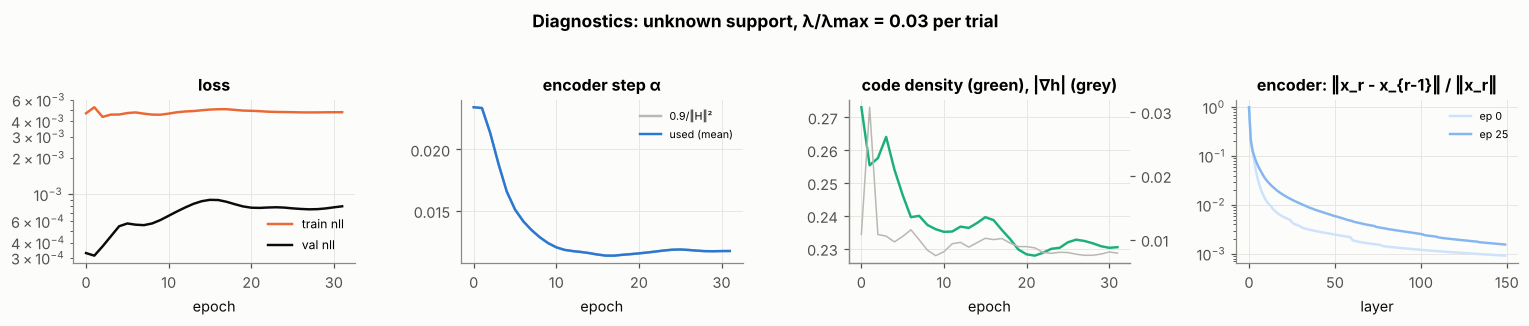

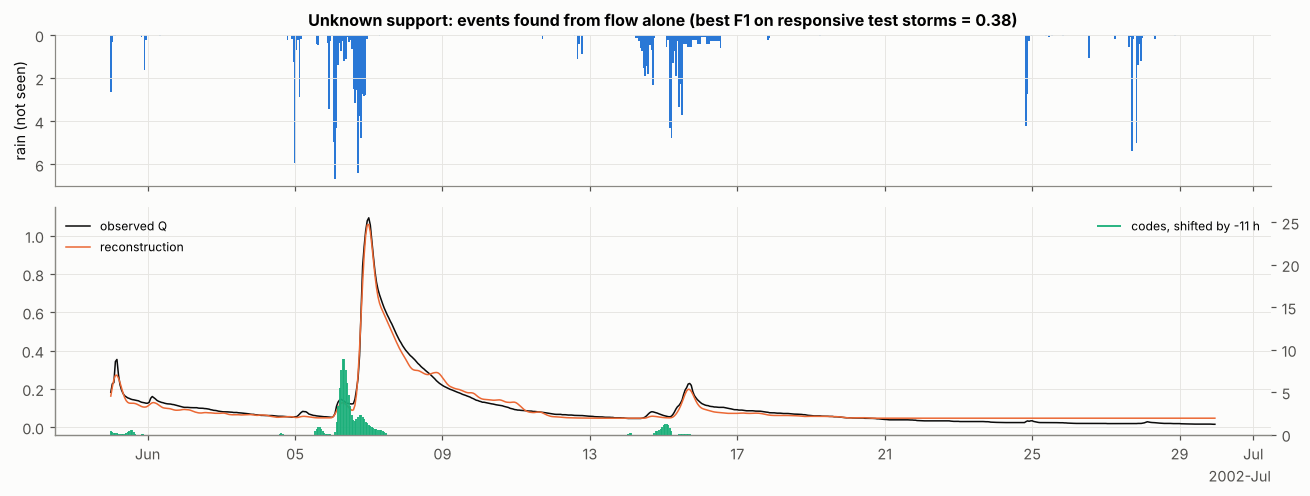

[INFO] unknown-support kernel: first index above 10% of peak = 0 h, peak at 4 h; code offset vs rain = 11 h (the shift gauge)


In [28]:
best_ratio = max(free_runs, key=lambda k: free_runs[k]["best"].f1)
fr = free_runs[best_ratio]
plot_diagnostics(fr["lg"].dir, f"Diagnostics: unknown support, λ/λmax = {best_ratio} per trial", "07_free_diagnostics")
j = 2
ti = D["test"]["idx"][j]
t_abs = Q_all.index[starts[ti]:starts[ti] + T_TRIAL]
off = int(fr["best"].offset)
fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.5]))
axes[0].bar(t_abs, D["test"]["P"][j, L_DEFAULT - 1:].numpy(), width=1 / 24, color=C["rain"])
axes[0].invert_yaxis(); axes[0].set_ylabel("rain (not seen)")
xcode = fr["ev"]["x"][j].sum(0).numpy()
idx_shift = np.arange(T_TRIAL + L_DEFAULT - 1) - (L_DEFAULT - 1) - off
ok = (idx_shift >= 0) & (idx_shift < T_TRIAL)
axes[1].plot(t_abs, D["test"]["Y"][j] * Q_SCALE, color=C["flow"], lw=1, label="observed Q")
axes[1].plot(t_abs, fr["ev"]["yhat"][j] * Q_SCALE, color=C["dunl"], lw=1, label="reconstruction")
ax2 = axes[1].twinx(); ax2.grid(False)
ax2.vlines(t_abs[idx_shift[ok]], 0, xcode[ok], color=C["fir"], lw=1.2, label=f"codes, shifted by {-off} h")
ax2.set_ylim(0, max(1e-6, xcode.max()) * 3)
axes[1].legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
axes[0].set_title(f"Unknown support: events found from flow alone (best F1 on responsive test storms = {fr['best'].f1:.2f})")
fig.tight_layout(); savefig(fig, "07_free_trial"); plt.show()

hf = fr["model"].h.detach().numpy()[0]
log.info(f"unknown-support kernel: first index above 10% of peak = {int(np.argmax(hf > 0.1*hf.max()))} h, "
         f"peak at {int(hf.argmax())} h; code offset vs rain = {off} h (the shift gauge)")

What to see here:

* The codes come in **bursts**, not single spikes: with per-hour codes and a smooth
  kernel, many neighbouring code positions explain the same rise almost equally
  well (the near-parallel columns again). Sparsity thins the burst but does not
  collapse it to one onset.
* The burst sits **hours away from the rain onset** (the offset in the log). That
  offset is the shift gauge: the model cannot tell "kernel starts late" from
  "event happened late". Any event-timing claim from unknown-support DUNL needs a
  convention that fixes this gauge.
* Check the diagnostics panel: if the training loss barely moves, the kernel stayed
  close to its gamma initialization, and the result is mostly the encoder's work.
  Blind kernel learning from a single gauge is hard; the paper's thalamus example
  had many neurons and group sparsity to tie the events together.

## 8. Parameter variations

Each sweep changes one setting from the K = 1 known-support baseline and records
held-out reconstruction NSE, training time, and how the kernel changes. All runs
land in `summary.csv`.

| setting | why it matters |
|---|---|
| `R` encoder depth | accuracy of the inner solve vs cost; the training gradient depends on it |
| `grad_through_encoder` | DUNL's unrolled gradient vs classical alternating minimization |
| `L` kernel length | too short cuts the recession (health check), too long adds noise |
| `beta_smooth` | kernel roughness vs fit |
| `K` with shared support | identifiability: loss plateau, kernel redundancy, seed stability |
| `step_frac` | encoder stability (above 2 the inner solve diverges) |
| `step_mode` at `R = 20` | paper's step (`full`) vs support-aware step: same depth, more progress per layer |
| `accel` at `R = 20` | ISTA layers (paper) vs FISTA layers, same depth and cost |

In [29]:
def run_variant(name, **kw):
    base = dict(K=1, L=L_DEFAULT, R=60, support="known", epochs=150, patience=25, trace_every=50)
    base.update(kw)
    cfg = DUNLConfig(name=name, **base)
    Ds = {s: subset(s, cfg.L) for s in ["train", "val", "test"]}
    mdl, lg, met = train_dunl(cfg, Ds["train"], Ds["val"], verbose=False)
    evv = evaluate(mdl, Ds["test"])
    met.update(test_nse=evv["nse"], peak_lag=[int(i) for i in mdl.h.argmax(1)])
    lg.finish(cfg, met)
    log.info(f"[sweep] {name:28s} test NSE {evv['nse']:.4f}  val nll {met['best_val_nll']:.5f}  "
             f"{met['train_sec']:6.1f}s  warnings {lg.warn_count}")
    return dict(name=name, model=mdl, test_nse=evv["nse"], val_nll=met["best_val_nll"], sec=met["train_sec"],
                warnings=lg.warn_count, cfg=cfg)

sweeps = {}
sweeps["R"] = [run_variant(f"sweep_R{R}", R=R) for R in [5, 20, 60, 150]]
sweeps["grad"] = [run_variant(f"sweep_grad_{g}", grad_through_encoder=g) for g in [True, False]]
sweeps["L"] = [run_variant(f"sweep_L{L}", L=L) for L in [48, 120, 240]]
sweeps["beta"] = [run_variant(f"sweep_beta{b}", beta_smooth=b) for b in [0.0, 1e-3, 1e-1]]
sweeps["K"] = [run_variant(f"sweep_K{K}_s{s}", K=K, seed=s) for K in [1, 2, 3] for s in [0, 1]]
sweeps["step"] = [run_variant(f"sweep_step{f}", step_frac=f, epochs=40) for f in [0.5, 0.9, 1.8, 2.5]]
sweeps["step_mode"] = [run_variant(f"sweep_stepmode_{m}_R20", step_mode=m, R=20) for m in ["full", "support"]]
sweeps["accel"] = [run_variant(f"sweep_accel_{a_}_R20", accel=a_, R=20) for a_ in ["none", "fista"]]

[WARNING] epoch 0: encoder not converged (last-layer rel change 4.94e-02); consider larger R


[INFO] early stop at epoch 44 (best 19)


[INFO] [sweep] sweep_R5                     test NSE 0.9234  val nll 0.00523     2.0s  warnings 1


[WARNING] epoch 0: encoder not converged (last-layer rel change 1.47e-02); consider larger R


[INFO] early stop at epoch 42 (best 17)


[INFO] [sweep] sweep_R20                    test NSE 0.9521  val nll 0.00430     3.4s  warnings 1


... (56 outputs left out)

[INFO] [sweep] sweep_accel_none_R20         test NSE 0.9521  val nll 0.00430     3.6s  warnings 1


[WARNING] epoch 0: encoder not converged (last-layer rel change 2.65e-02); consider larger R


[INFO] early stop at epoch 41 (best 16)


[INFO] [sweep] sweep_accel_fista_R20        test NSE 0.9623  val nll 0.00393     3.5s  warnings 1


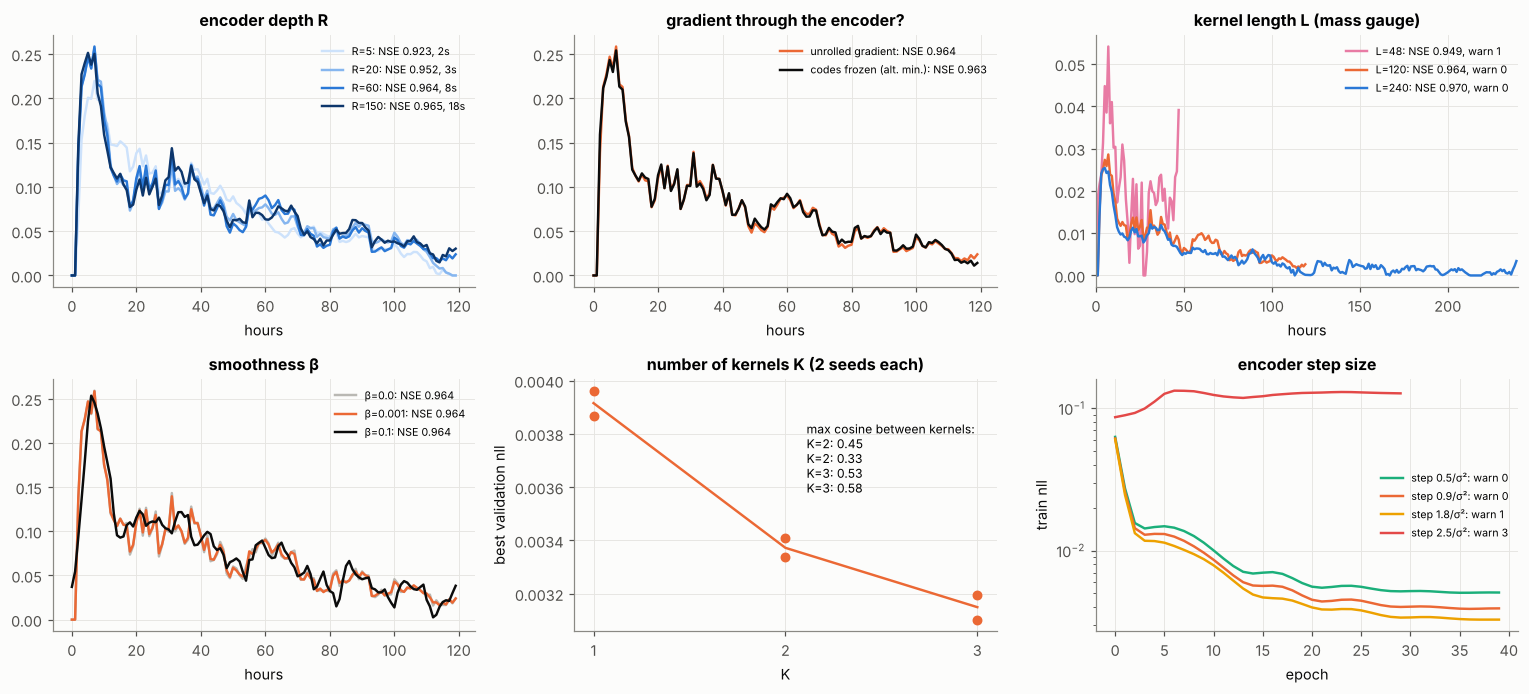

,sweep,run,test_nse,val_nll,sec,warnings
0,R,sweep_R5,0.9234,0.005231,2.0,1
1,R,sweep_R20,0.9521,0.004300,3.4,1
2,R,sweep_R60,0.9640,0.003962,7.5,0
3,R,sweep_R150,0.9646,0.003705,18.1,1
4,grad,sweep_grad_True,0.9640,0.003962,7.5,0
5,grad,sweep_grad_False,0.9627,0.003966,4.4,0
6,L,sweep_L48,0.9494,0.004430,5.8,1
7,L,sweep_L120,0.9640,0.003962,7.6,0
8,L,sweep_L240,0.9698,0.003612,12.2,0
9,beta,sweep_beta0.0,0.9640,0.003961,7.5,0


In [30]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
# R
ax = axes[0, 0]
ref_h = sweeps["R"][-1]["model"].h.detach().numpy()[0]
for r_, col in zip(sweeps["R"], ["#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"]):
    ax.plot(r_["model"].h.detach().numpy()[0], color=col, label=f"R={r_['cfg'].R}: NSE {r_['test_nse']:.3f}, {r_['sec']:.0f}s")
ax.set_title("encoder depth R"); ax.legend(fontsize=7)
# grad
ax = axes[0, 1]
for r_, col in zip(sweeps["grad"], [C["dunl"], C["flow"]]):
    lbl = "unrolled gradient" if r_["cfg"].grad_through_encoder else "codes frozen (alt. min.)"
    ax.plot(r_["model"].h.detach().numpy()[0], color=col, label=f"{lbl}: NSE {r_['test_nse']:.3f}")
ax.set_title("gradient through the encoder?"); ax.legend(fontsize=7)
# L
ax = axes[0, 2]
for r_, col in zip(sweeps["L"], [C["eta"], C["dunl"], C["rain"]]):
    hh = r_["model"].h.detach().numpy()[0]
    ax.plot(hh / hh.sum(), color=col, label=f"L={r_['cfg'].L}: NSE {r_['test_nse']:.3f}, warn {r_['warnings']}")
ax.set_title("kernel length L (mass gauge)"); ax.legend(fontsize=7); ax.set_xlim(0, 240)
# beta
ax = axes[1, 0]
for r_, col in zip(sweeps["beta"], ["#b9b8b3", C["dunl"], C["flow"]]):
    ax.plot(r_["model"].h.detach().numpy()[0], color=col, label=f"β={r_['cfg'].beta_smooth}: NSE {r_['test_nse']:.3f}")
ax.set_title("smoothness β"); ax.legend(fontsize=7)
# K
ax = axes[1, 1]
kdf = pd.DataFrame([dict(K=r_["cfg"].K, seed=r_["cfg"].seed, val=r_["val_nll"], test=r_["test_nse"]) for r_ in sweeps["K"]])
for K_ in [1, 2, 3]:
    sub = kdf[kdf.K == K_]
    ax.scatter([K_] * len(sub), sub.val, color=C["dunl"], s=30, zorder=3)
ax.plot(kdf.groupby("K").val.mean(), color=C["dunl"])
ax.set_xticks([1, 2, 3]); ax.set_xlabel("K"); ax.set_ylabel("best validation nll")
red = []
for r_ in sweeps["K"]:
    if r_["cfg"].K > 1:
        hh = r_["model"].h.detach().numpy(); hn_ = hh / np.linalg.norm(hh, axis=1, keepdims=True)
        cm_ = hn_ @ hn_.T; red.append((r_["cfg"].K, np.max(cm_[np.triu_indices(len(hh), 1)])))
txt = "max cosine between kernels:\n" + "\n".join(f"K={k}: {v:.2f}" for k, v in red)
ax.text(0.55, 0.55, txt, transform=ax.transAxes, fontsize=8)
ax.set_title("number of kernels K (2 seeds each)")
# step
ax = axes[1, 2]
for r_, col in zip(sweeps["step"], [C["fir"], C["dunl"], C["gamma"], C["bad"]]):
    ep_ = read_jsonl(os.path.join(RUN_ROOT, r_["name"], "train_log.jsonl"))
    ax.semilogy(ep_.epoch, ep_.nll, color=col, label=f"step {r_['cfg'].step_frac}/σ²: warn {r_['warnings']}")
ax.set_title("encoder step size"); ax.legend(fontsize=7); ax.set_xlabel("epoch"); ax.set_ylabel("train nll")
for ax in [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0]]:
    ax.set_xlabel("hours")
fig.tight_layout(); savefig(fig, "08_sweeps"); plt.show()

sweep_table = pd.DataFrame([dict(sweep=k, run=r_["name"], test_nse=round(r_["test_nse"], 4),
                                 val_nll=r_["val_nll"], sec=r_["sec"], warnings=r_["warnings"])
                            for k, v in sweeps.items() for r_ in v])
sweep_table.to_csv(os.path.join(RUN_ROOT, "sweep_table.csv"), index=False)
sweep_table

## 9. Baselines and comparison

**Important: two different tasks.** DUNL is an *analysis* model: its encoder reads
the flow `y` to infer codes. So its reconstruction NSE is not a forecast and cannot
be compared with models that predict flow from rain. We compare on three fair
grounds:

1. **Prediction from rain** on the test year, using each method's kernel as a unit
   hydrograph: `Q̂ = c · (h ∗ P) + b`, with `c, b` fitted on training data. For DUNL
   this uses the learned kernel(s) and ignores the inferred amplitudes.

   Then the step DUNL makes possible: its codes are **per-event amplitudes**, i.e.
   an estimate of effective rain for every rainy hour. We fit a small model for them,
   `rc(t) = sigmoid(w · f(t))` with features from rain and calendar only (5-day and
   30-day antecedent rain, season), and forecast with `Q̂ = c · h ∗ (rc · P) + b`.
   As an ablation, the same model is fitted end-to-end on `Q` without using DUNL's
   codes. This tells us whether the codes add information or only convenience.
2. **Kernel stability** under resampling of the training windows.
3. **Event detection** from flow alone (DUNL unknown support vs peak finding).

Baselines:

| method | kernel | amplitudes | analogue in the paper |
|---|---|---|---|
| event-triggered average | average around isolated storms | none | windowed averaging |
| FIR least squares (ridge) | free, `L` lags | fixed = rain × constant | GLM with a free filter |
| gamma / Nash cascade | parametric, 2 shape params | fixed = rain × constant | GLM with a fixed basis |
| DUNL kernel + amplitude model | learned by DUNL | `rc(t)·P`, `rc` fitted to DUNL codes | (new: uses the codes) |
| GRU | none (black box) | none | LFADS-style deep model |
| peak finding on Q | none | none | peak-finding baseline (Fig. 4F) |

In [31]:
def lagged_design(pctx, L, T=T_TRIAL):
    """pctx: (J, T+L-1) rain with context -> design (J*T, L) with column l = P[t-l]."""
    J = pctx.shape[0]
    X = np.stack([pctx[:, L - 1 - l:L - 1 - l + T] for l in range(L)], axis=-1)
    return X.reshape(J * T, L)

def flat(d):
    return d["Y"].numpy().reshape(-1), d["W"].numpy().reshape(-1).astype(bool)

def fit_scale(conv_list, d):
    """Least squares for c_k and b in  y ≈ Σ c_k (h_k ∗ P) + b  on observed bins."""
    y, w = flat(d)
    A = np.column_stack(conv_list + [np.ones_like(y)])
    coef = np.linalg.lstsq(A[w], y[w], rcond=None)[0]
    return coef

def conv_with_rain(h, d, L):
    X = lagged_design(d["P"].numpy(), L)
    return X @ h

def nse_np(y, yh, w):
    y, yh = y[w], yh[w]
    return 1 - np.sum((y - yh) ** 2) / np.sum((y - y.mean()) ** 2)

def kge_np(y, yh, w):
    y, yh = y[w], yh[w]
    r_ = np.corrcoef(y, yh)[0, 1]
    return 1 - np.sqrt((r_ - 1) ** 2 + (yh.std() / y.std() - 1) ** 2 + (yh.mean() / y.mean() - 1) ** 2)

def peak_error(y, yh, d, top=10):
    """Mean relative error on the largest test-storm peaks (within 48 h after onset)."""
    yy = y.reshape(len(d["idx"]), T_TRIAL); hh = yh.reshape(len(d["idx"]), T_TRIAL)
    errs = []
    for row_i, ti in enumerate(d["idx"]):
        for s in storms.i_start:
            o = s - starts[ti]
            if 0 <= o < T_TRIAL - 48:
                errs.append((yy[row_i, o:o + 48].max(), hh[row_i, o:o + 48].max()))
    errs = sorted(errs, key=lambda e: -e[0])[:top]
    return float(np.mean([abs(p - o) / o for o, p in errs])) if errs else np.nan

D_trval = D_full_tr
pred = {}

# --- FIR ridge (unit hydrograph by regression), ridge weight chosen on validation ---
Xtr = lagged_design(D["train"]["P"].numpy(), L_DEFAULT); ytr, wtr = flat(D["train"])
Xva = lagged_design(D["val"]["P"].numpy(), L_DEFAULT); yva, wva = flat(D["val"])
best_fir = None
for rho_ in [1e-2, 1e-1, 1, 10, 100, 1e3, 1e4, 1e5]:
    A = np.column_stack([Xtr, np.ones(len(ytr))])[wtr]
    Rg = rho_ * np.eye(L_DEFAULT + 1); Rg[-1, -1] = 0
    coef = np.linalg.solve(A.T @ A + Rg, A.T @ ytr[wtr])
    resid = (np.column_stack([Xva, np.ones(len(yva))]) @ coef - yva)[wva]
    v = float(np.mean(resid ** 2))       # MSE, not NSE: validation windows are low-flow, so NSE is unstable there
    if best_fir is None or v < best_fir[0]:
        best_fir = (v, rho_, coef)
log.info(f"FIR ridge: chosen ridge weight {best_fir[1]} (val MSE {best_fir[0]:.4f})")
if best_fir[1] in (1e-2, 1e5):
    log.warning("FIR ridge weight is at the edge of the grid; widen the grid")
h_fir = best_fir[2][:-1]

# --- non-negative FIR (NNLS) ---
A = np.column_stack([Xtr, np.ones(len(ytr))])[wtr]
coef_nn, _ = optimize.nnls(A, ytr[wtr])
h_fir_nn = coef_nn[:-1]

# --- gamma (Nash cascade): 2 shape params, scale c and offset b ---
Xtv = lagged_design(D_trval["P"].numpy(), L_DEFAULT); ytv, wtv = flat(D_trval)
def gamma_resid(theta):
    n_, k_, c_, b_ = theta
    return (Xtv[wtv] @ (c_ * gamma_kernel(L_DEFAULT, n_, k_)) + b_) - ytv[wtv]
g_fit = optimize.least_squares(gamma_resid, x0=[2.0, 5.0, 1.0, 0.1], bounds=([0.5, 0.3, 0, -5], [20, 80, 1e3, 5]))
h_gam = gamma_kernel(L_DEFAULT, g_fit.x[0], g_fit.x[1])
log.info(f"gamma fit: shape={g_fit.x[0]:.2f}, scale={g_fit.x[1]:.2f} h, peak≈{(g_fit.x[0]-1)*g_fit.x[1]:.1f} h")

# --- event-triggered average (isolated storms, from Section 3b) ---
h_eta = np.clip(eta_iso[24:24 + L_DEFAULT], 0, None)

# --- assemble predictions from rain on the test year (scale and offset fitted on train+val) ---
def kernel_predict(hs, name):
    convs_tv = [conv_with_rain(h_, D_trval, L_DEFAULT) for h_ in hs]
    coef = fit_scale(convs_tv, D_trval)
    convs_te = [conv_with_rain(h_, D["test"], L_DEFAULT) for h_ in hs]
    yh = np.column_stack(convs_te + [np.ones(len(convs_te[0]))]) @ coef
    pred[name] = yh
    return yh

kernel_predict([m_k1.h.detach().numpy()[0]], "DUNL K=1 kernel")
kernel_predict([h for h in k2_models[0][0].h.detach().numpy()], "DUNL K=2 kernels")
kernel_predict([h_fir], "FIR ridge")
kernel_predict([h_fir_nn], "FIR non-negative")
kernel_predict([h_gam], "gamma (Nash)")
kernel_predict([h_eta], "event-triggered avg")

# --- amplitude model: a state-dependent runoff coefficient rc(t) = sigmoid(f(t)·w) ---
# features use rain and the calendar only, so the model can still forecast from rain
api5_all = signal.lfilter([1.0], [1.0, -np.exp(-1 / 120.0)], P_all.values)
api30_all = signal.lfilter([1.0], [1.0, -np.exp(-1 / 720.0)], P_all.values)
doy_all = P_all.index.dayofyear.values
F_all = np.column_stack([np.log1p(api5_all), np.log1p(api30_all),
                         np.sin(2 * np.pi * doy_all / 365.25), np.cos(2 * np.pi * doy_all / 365.25)])
F_mu, F_sd = F_all.mean(0), F_all.std(0)
F_all = (F_all - F_mu) / F_sd

def features_ctx(d, L):
    """Features on each trial's code positions: absolute index starts[ti]-(L-1) .. starts[ti]+T-1."""
    return np.stack([F_all[starts[ti] - (L - 1):starts[ti] + T_TRIAL] for ti in d["idx"]])

def conv_trials(u, h, L):
    """u: (J, T+L-1) on code positions -> (J*T,) flow, same alignment as H_op."""
    return np.concatenate([np.convolve(row, h)[L - 1:L - 1 + T_TRIAL] for row in u])

def rc_of(w_, Fc):
    return 1 / (1 + np.exp(-(w_[0] + Fc @ w_[1:])))

h_d = m_k1.h.detach().numpy()[0]; hsum_d = h_d.sum()

# (a) two-stage: fit rc on DUNL's inferred effective rain (codes, mass gauge, mm per hour)
ev_trval = evaluate(m_k1, D_trval)
e_mm = ev_trval["x"][:, 0].numpy() * hsum_d * Q_SCALE
P_tv = D_trval["P"].numpy(); Fc_tv = features_ctx(D_trval, L_DEFAULT)
wet_tv = P_tv > WET_THR
def rc_resid_codes(w_):
    return (rc_of(w_, Fc_tv[wet_tv]) * P_tv[wet_tv] - e_mm[wet_tv])
fit_a = optimize.least_squares(rc_resid_codes, x0=np.zeros(5))
log.info(f"amplitude model on DUNL codes: w={np.round(fit_a.x, 3).tolist()}, "
         f"rc range on train {rc_of(fit_a.x, Fc_tv[wet_tv]).min():.3f}..{rc_of(fit_a.x, Fc_tv[wet_tv]).max():.3f}")

def amp_predict(w_, d, h, hsum):
    u = rc_of(w_, features_ctx(d, L_DEFAULT)) * d["P"].numpy() / (hsum * Q_SCALE)
    return conv_trials(u, h, L_DEFAULT)

coef = fit_scale([amp_predict(fit_a.x, D_trval, h_d, hsum_d)], D_trval)
pred["DUNL kernel + amplitude model (fit on codes)"] = coef[0] * amp_predict(fit_a.x, D["test"], h_d, hsum_d) + coef[1]

# (b) ablation: same kernel, same amplitude model, but w fitted end-to-end on Q (no DUNL codes)
ytv_, wtv_ = flat(D_trval)
def rc_resid_flow(theta):
    w_, c_, b_ = theta[:5], theta[5], theta[6]
    return (c_ * amp_predict(w_, D_trval, h_d, hsum_d) + b_ - ytv_)[wtv_]
fit_b = optimize.least_squares(rc_resid_flow, x0=np.r_[fit_a.x, coef])
pred["DUNL kernel + amplitude model (fit end-to-end on Q)"] = (
    fit_b.x[5] * amp_predict(fit_b.x[:5], D["test"], h_d, hsum_d) + fit_b.x[6])
log.info(f"amplitude model end-to-end: w={np.round(fit_b.x[:5], 3).tolist()}")

# --- GRU black box: rain sequence -> flow ---
class GRUModel(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.gru = nn.GRU(1, hidden, batch_first=True); self.out = nn.Linear(hidden, 1)
    def forward(self, p):
        return self.out(self.gru(p.unsqueeze(-1))[0]).squeeze(-1)

def train_gru(epochs=300, seed=0, hidden=32, burn_in=100):
    """Rain sequence -> flow (rain only, like the kernel models).
    Validation loss is noisy and drops only after ~100 epochs, so the best model is
    picked among epochs after a burn-in instead of stopping early."""
    torch.manual_seed(seed)
    gm = GRUModel(hidden); opt = torch.optim.Adam(gm.parameters(), lr=1e-2, weight_decay=1e-4)
    def inp(d):
        return to_t(P_ctx_np[d["idx"]])
    ptr, pva = inp(D["train"]), inp(D["val"])
    gl = open(os.path.join(RUN_ROOT, "gru_train_log.jsonl"), "w")
    t0, best, stale = time.time(), (np.inf, None, -1), 0
    for ep in range(epochs):
        out = gm(ptr)[:, L_MAX - 1:]
        loss = ((D["train"]["W"] * (out - D["train"]["Y"])) ** 2).sum() / D["train"]["W"].sum()
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(gm.parameters(), 1.0); opt.step()
        with torch.no_grad():
            ov = gm(pva)[:, L_MAX - 1:]
            vl = float(((D["val"]["W"] * (ov - D["val"]["Y"])) ** 2).sum() / D["val"]["W"].sum())
        gl.write(json.dumps(dict(epoch=ep, loss=float(loss), val_loss=vl, sec=time.time() - t0)) + "\n")
        if ep >= burn_in and vl < best[0]:
            best = (vl, {k: v.clone() for k, v in gm.state_dict().items()}, ep)
    gl.close()
    gm.load_state_dict(best[1])
    with torch.no_grad():
        yh = gm(inp(D["test"]))[:, L_MAX - 1:].numpy().reshape(-1)
    log.info(f"GRU: best val loss {best[0]:.4f} at epoch {best[2]}, stopped at {ep}, {time.time()-t0:.1f}s")
    return gm, yh

gru_model, pred["GRU (black box)"] = train_gru()

yte, wte = flat(D["test"])
cmp_rows = []
for name, yh in pred.items():
    cmp_rows.append(dict(method=name, NSE=nse_np(yte, yh, wte), KGE=kge_np(yte, yh, wte),
                         peak_rel_error=peak_error(yte, yh, D["test"]),
                         interpretable_kernel=name != "GRU (black box)",
                         state_dependent_amplitude="amplitude model" in name))
cmp_table = pd.DataFrame(cmp_rows).round(3).sort_values("NSE", ascending=False)
cmp_table.to_csv(os.path.join(RUN_ROOT, "comparison_prediction.csv"), index=False)
log.info("prediction-from-rain comparison:\n" + cmp_table.to_string(index=False))
cmp_table

[INFO] FIR ridge: chosen ridge weight 100000.0 (val MSE 0.1057)


[WARNING] FIR ridge weight is at the edge of the grid; widen the grid


[INFO] gamma fit: shape=1.20, scale=58.71 h, peak≈12.0 h


[INFO] amplitude model on DUNL codes: w=[-9.006, -0.396, 2.637, 4.653, -1.629], rc range on train 0.000..0.647


[INFO] amplitude model end-to-end: w=[-16.951, -4.4, 12.19, 11.416, -2.408]


[INFO] GRU: best val loss 0.0307 at epoch 237, stopped at 299, 81.0s


[INFO] prediction-from-rain comparison:
                                             method   NSE    KGE  peak_rel_error  interpretable_kernel  state_dependent_amplitude
       DUNL kernel + amplitude model (fit on codes) 0.545  0.596           0.756                  True                       True
DUNL kernel + amplitude model (fit end-to-end on Q) 0.477  0.527           0.753                  True                       True
                                    GRU (black box) 0.229  0.190           0.748                 False                      False
                                       gamma (Nash) 0.196  0.037           0.763                  True                      False
                                   FIR non-negative 0.195  0.037           0.756                  True                      False
                                          FIR ridge 0.194  0.036           0.766                  True                      False
                                   DUNL K=2 kernel

,method,NSE,KGE,peak_rel_error,interpretable_kernel,state_dependent_amplitude
6,DUNL kernel + amplitude model (fit on codes),0.545,0.596,0.756,True,True
7,DUNL kernel + amplitude model (fit end-to-end ...,0.477,0.527,0.753,True,True
8,GRU (black box),0.229,0.190,0.748,False,False
4,gamma (Nash),0.196,0.037,0.763,True,False
3,FIR non-negative,0.195,0.037,0.756,True,False
2,FIR ridge,0.194,0.036,0.766,True,False
1,DUNL K=2 kernels,0.193,0.033,0.735,True,False
0,DUNL K=1 kernel,0.187,0.027,0.724,True,False
5,event-triggered avg,0.051,-0.123,0.774,True,False


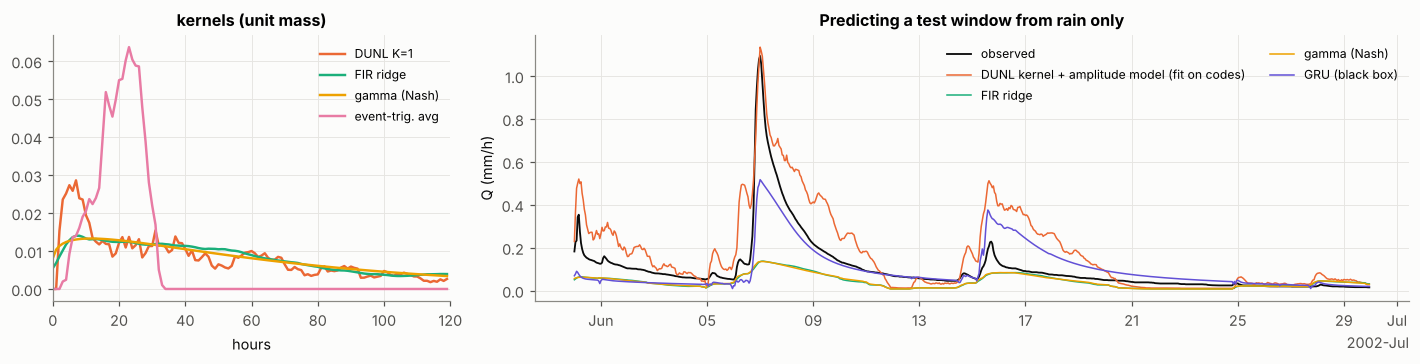

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1, 2.2]))
ax = axes[0]
for name, h_, col in [("DUNL K=1", m_k1.h.detach().numpy()[0], C["dunl"]), ("FIR ridge", h_fir, C["fir"]),
                      ("gamma (Nash)", h_gam, C["gamma"]), ("event-trig. avg", h_eta, C["eta"])]:
    ax.plot(h_ / np.abs(h_).sum(), color=col, label=name)
ax.set_title("kernels (unit mass)"); ax.legend(fontsize=8); ax.set_xlabel("hours"); ax.set_xlim(0, 120)
ax = axes[1]
j = 2
sl = slice(j * T_TRIAL, (j + 1) * T_TRIAL)
t_abs = Q_all.index[starts[D["test"]["idx"][j]]:starts[D["test"]["idx"][j]] + T_TRIAL]
ax.plot(t_abs, np.where(wte[sl], yte[sl], np.nan) * Q_SCALE, color=C["flow"], lw=1.2, label="observed")
for name, col in [("DUNL kernel + amplitude model (fit on codes)", C["dunl"]), ("FIR ridge", C["fir"]),
                  ("gamma (Nash)", C["gamma"]), ("GRU (black box)", C["gru"])]:
    ax.plot(t_abs, pred[name][sl] * Q_SCALE, color=col, lw=1, label=name)
ax.set_title("Predicting a test window from rain only"); ax.legend(fontsize=8, ncol=2); ax.set_ylabel("Q (mm/h)")
fig.tight_layout(); savefig(fig, "09_prediction"); plt.show()

Reading the prediction table:

* Every **fixed-amplitude** kernel model (DUNL kernel alone, FIR, gamma) lands at
  about the same score. With one runoff coefficient for all storms, the kernel shape
  hardly matters: the error is dominated by the seasonal and wetness-driven swings
  in how much rain becomes flow (Section 2 and 3d).
* Adding a **state-dependent amplitude** is what moves the score. Fitting that
  amplitude model to DUNL's inferred effective rain beats fitting the same model
  end-to-end on flow. The codes turn a hard nonlinear fit into a simple regression
  on a clean target, which is the practical value of per-event amplitudes.
* The **GRU** sees only 12 training windows. It learns something, but a black box
  needs far more data to discover the wetness state on its own. On long, multi-basin
  records (the full CAMELS set) recurrent networks are very strong, so this row says
  something about the data-limited regime, not about recurrent models in general.

### 9.1 Kernel stability under resampling

Resample the training windows with replacement 5 times, refit DUNL (K = 1) and the
FIR kernel, and measure how much the kernel moves: mean pairwise cosine similarity
and the spread of the peak lag. A kernel you want to interpret must be stable.

[INFO] early stop at epoch 41 (best 16)


[WARNING] boot_dunl_0 kernel 0 tail still 10.2% of peak; L may be too short


[INFO] early stop at epoch 40 (best 15)


[INFO] early stop at epoch 38 (best 13)


[INFO] early stop at epoch 35 (best 10)


[INFO] early stop at epoch 34 (best 9)


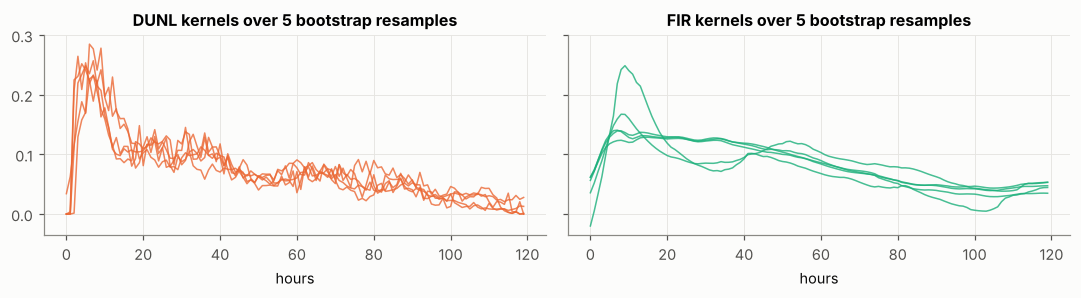

[INFO] kernel stability:
method  mean_pairwise_cosine  peak_lag_mean  peak_lag_sd  negative_mass_frac
  dunl                 0.953            5.8        2.135                 0.0
   fir                 0.960            9.4        2.871                 0.0


,method,mean_pairwise_cosine,peak_lag_mean,peak_lag_sd,negative_mass_frac
0,dunl,0.953,5.8,2.135,0.0
1,fir,0.960,9.4,2.871,0.0


In [33]:
rng_b = np.random.default_rng(0)
tv_rows = np.arange(len(D_trval["idx"]))
boot = dict(dunl=[], fir=[])
for b_ in range(5):
    pick = rng_b.choice(tv_rows, len(tv_rows), replace=True)
    db = {k: (v[pick] if torch.is_tensor(v) else v[pick]) for k, v in D_trval.items()}
    cfg = DUNLConfig(name=f"boot_dunl_{b_}", K=1, L=L_DEFAULT, R=60, support="known", epochs=120,
                     patience=25, seed=b_, trace_every=0)
    mdl, lg, met = train_dunl(cfg, db, D["val"], verbose=False); lg.finish(cfg, met)
    boot["dunl"].append(mdl.h.detach().numpy()[0])
    Xb = lagged_design(db["P"].numpy(), L_DEFAULT); yb, wb = flat(db)
    A = np.column_stack([Xb, np.ones(len(yb))])[wb]
    Rg = best_fir[1] * np.eye(L_DEFAULT + 1); Rg[-1, -1] = 0
    boot["fir"].append(np.linalg.solve(A.T @ A + Rg, A.T @ yb[wb])[:-1])

stab_rows = []
for k_, hs in boot.items():
    Hs = np.array([h_ / np.linalg.norm(h_) for h_ in hs])
    cs = Hs @ Hs.T
    stab_rows.append(dict(method=k_, mean_pairwise_cosine=cs[np.triu_indices(len(Hs), 1)].mean(),
                          peak_lag_mean=np.mean([h_.argmax() for h_ in hs]),
                          peak_lag_sd=np.std([h_.argmax() for h_ in hs]),
                          negative_mass_frac=np.mean([np.clip(-h_, 0, None).sum() / np.abs(h_).sum() for h_ in hs])))
stab_table = pd.DataFrame(stab_rows).round(3)
stab_table.to_csv(os.path.join(RUN_ROOT, "comparison_stability.csv"), index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (k_, hs), col in zip(axes, boot.items(), [C["dunl"], C["fir"]]):
    for h_ in hs:
        ax.plot(h_ / np.linalg.norm(h_), color=col, lw=1, alpha=0.8)
    ax.set_title(f"{k_.upper()} kernels over 5 bootstrap resamples"); ax.set_xlabel("hours")
fig.tight_layout(); savefig(fig, "09_stability"); plt.show()
log.info("kernel stability:\n" + stab_table.to_string(index=False))
stab_table

Compare the two rows of the table. Cosine similarity measures overall shape;
the peak-lag spread measures what a hydrologist would read off the kernel (time to
peak). Things to look for in the plot: FIR kernels often end with an upturn at the
last lags (a window-edge artifact: the last lag soaks up rain from before the
window), and FIR can go negative, which DUNL's projection rules
out. Note that DUNL also estimates one amplitude per rainy hour, so its kernel is
learned from a harder problem than FIR's.

### 9.2 Event detection from flow alone

Peak finding on `Q` with a prominence threshold is the paper's baseline in Fig. 4F.
Its timing offset (peaks come after rain) is calibrated on the training years, the
same way as DUNL's shift gauge. Both methods are swept over their threshold and
scored on responsive test storms (±6 h), giving miss / false-alarm curves.

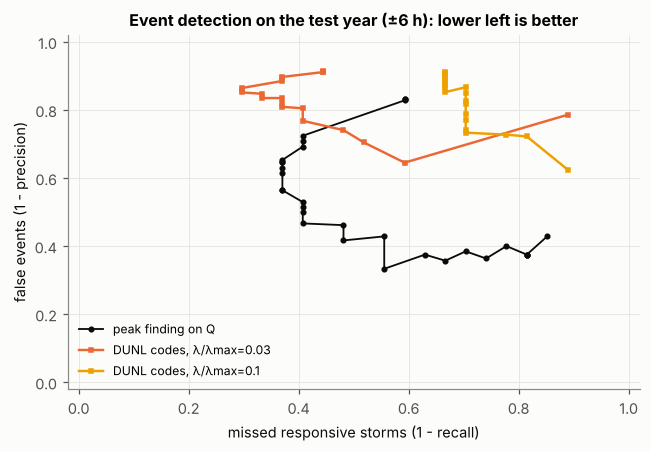

[INFO] event detection (best threshold each):
           method    F1  precision  recall  offset_h
peak finding on Q 0.561      0.533   0.593      14.0
 DUNL λ/λmax=0.03 0.379      0.355   0.407      11.0
  DUNL λ/λmax=0.1 0.281      0.267   0.296      12.0


,method,F1,precision,recall,offset_h
0,peak finding on Q,0.561,0.533,0.593,14.0
1,DUNL λ/λmax=0.03,0.379,0.355,0.407,11.0
2,DUNL λ/λmax=0.1,0.281,0.267,0.296,12.0


In [34]:
def peak_events(d, prom):
    out = []
    for row_i, ti in enumerate(d["idx"]):
        yy = d["Y"][row_i].numpy()
        pk, _ = signal.find_peaks(yy, prominence=prom, distance=STORM_GAP)
        out += list(starts[ti] + pk)
    return np.array(out)

true_tr, true_te = storms_in(D_full_tr), storms_in(D["test"])
curve = []
for prom in np.geomspace(0.005, 3, 30):
    off = estimate_offset(peak_events(D_full_tr, prom), true_tr)
    sc = match_events(peak_events(D["test"], prom) - off, true_te)
    curve.append(dict(prom=prom, offset=off, **sc))
curve = pd.DataFrame(curve)
curve.to_csv(os.path.join(RUN_ROOT, "peakfinding_curve.csv"), index=False)

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(1 - curve.recall, 1 - curve.precision, "o-", color=C["flow"], ms=3, lw=1.2, label="peak finding on Q")
for (ratio, fr_), col in zip(free_runs.items(), [C["dunl"], C["gamma"]]):
    cv = fr_["curve"]
    ax.plot(1 - cv.recall, 1 - cv.precision, "s-", color=col, ms=3, lw=1.6, label=f"DUNL codes, λ/λmax={ratio}")
ax.set_xlabel("missed responsive storms (1 - recall)"); ax.set_ylabel("false events (1 - precision)")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_title("Event detection on the test year (±6 h): lower left is better"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "09_event_detection"); plt.show()
best_pk = curve.loc[curve.f1.idxmax()]
det_table = pd.DataFrame([dict(method="peak finding on Q", F1=best_pk.f1, precision=best_pk.precision,
                               recall=best_pk.recall, offset_h=best_pk.offset)] +
                         [dict(method=f"DUNL λ/λmax={k}", F1=v["best"].f1, precision=v["best"].precision,
                               recall=v["best"].recall, offset_h=v["best"].offset) for k, v in free_runs.items()]).round(3)
det_table.to_csv(os.path.join(RUN_ROOT, "comparison_detection.csv"), index=False)
log.info("event detection (best threshold each):\n" + det_table.to_string(index=False))
det_table

On this task, at this site, **plain peak finding beats unknown-support DUNL**. That is
a useful negative result. One gauge, noisy low summer flows, per-hour codes that
smear into bursts, and the shift gauge all work against DUNL here. The paper's
advantage in Fig. 4F came with many simultaneously recorded neurons and group
sparsity. The hydrology analogue is several gauges in one basin sharing storm
times, which is a natural next experiment.

## 10. Summary

The cell below prints the key numbers from this run, read back from the saved files,
so the summary always matches what was actually computed.

In [35]:
summary = load_summary()
print("Runs logged:", len(summary), "| total warnings:", int(summary.warnings.sum()))
print("\nRuns with warnings (details in each run's warnings.txt):")
print(summary.loc[summary.warnings > 0, ["name", "warnings"]].to_string(index=False))
print("\nSynthetic identifiability:")
print(syn_table[["case", "encoder", "seed", "cos_quick", "cos_slow", "nll_learned_deep", "nll_true_deep", "verdict"]].to_string(index=False))
print(f"\nStorm runoff coefficient vs truth (synthetic): Spearman DUNL {rho_d:.2f}, window {rho_w:.2f}")
print(f"Storm runoff coefficient vs wetness (real):    Spearman DUNL {rd:.2f}, window {rw:.2f}")
print("\nPrediction from rain (test year):")
print(cmp_table.to_string(index=False))
print("\nKernel stability (bootstrap):")
print(stab_table.to_string(index=False))
print("\nEvent detection from flow (responsive test storms):")
print(det_table.to_string(index=False))
print(f"\nAll logs and figures: {os.path.abspath(RUN_ROOT)}")

Runs logged: 45 | total warnings: 23

Runs with warnings (details in each run's warnings.txt):
                      name  warnings
          real_known_K2_s0         1
          real_known_K2_s1         2
          real_known_K2_s2         2
                  sweep_R5         1
                 sweep_R20         1
                sweep_R150         1
                 sweep_L48         1
             sweep_beta0.1         1
               sweep_K2_s0         1
               sweep_K2_s1         1
               sweep_K3_s0         1
               sweep_K3_s1         1
             sweep_step1.8         1
             sweep_step2.5         3
   sweep_stepmode_full_R20         1
sweep_stepmode_support_R20         1
      sweep_accel_none_R20         1
     sweep_accel_fista_R20         1
               boot_dunl_0         1

Synthetic identifiability:
      case encoder  seed  cos_quick  cos_slow  nll_learned_deep  nll_true_deep                                                   verdict


### What to take from this notebook

The printed summary above has the numbers for this run. The qualitative points:

**On the method**
* The operator view is exact and cheap: adjoint test, FFT diagonalization, and a
  one-FFT step-size bound that can be recomputed every step.
* Step size: the safe step is `1/σ²`. The `1/σ` written in the paper's text diverges
  here. With known support, the right constant is `‖H E‖²`, which allows a larger
  step and gives a better fit at the same encoder depth (`step_mode` sweep).
* Known support turns DUNL into a bilinear GLM: free kernel shape and a free
  amplitude per event. On synthetic data it recovers the quick kernel every time,
  and its storm amplitudes track the true runoff coefficient far better than windows.
* **Identifiability of shared-support kernels is the central issue.** A deep-solve
  loss comparison against the true kernels separates "not identifiable" from
  "training failed". Amplitudes confined to a narrow cone give wrong kernels that
  fit as well as the truth; scattered amplitudes make the truth strictly best. This
  is open question A1, now with a working test bed.
* **The encoder depth biases what is learned.** Training through a truncated ISTA
  encoder favours kernels whose inner problem is easy, not the true ones. FISTA
  layers, same cost, largely remove that bias in the synthetic test.
* Unknown support works for reconstruction, but event timing is limited by the
  shift gauge and by bursts of near-equivalent codes. Here peak finding wins.

**On hydrology**
* The learned unit hydrograph peaks within hours, as expected for a small, steep
  basin, with a long slow tail that a single kernel cannot separate from baseflow.
* Event amplitudes depend strongly on wetness and season. A fixed-amplitude model
  (FIR, gamma, DUNL kernel alone) cannot capture that; a model for DUNL's codes can,
  and that is where the forecast skill comes from.

### Back to the research path

| open question (from our notes) | where it shows up here |
|---|---|
| A1 identifiability of shared-support kernels | Section 6 (co-active case), 7.3 (K=2 seeds), 8 (K sweep) |
| A2 shift gauge | Section 7.4 (offset estimate), 9.2 |
| A3 step size / Bregman | Section 5.2 |
| A4 what the unrolled gradient optimizes | Section 8 (`grad_through_encoder`, `R` sweep) |
| C1 event-process prior | the amplitude model needed for forecasting (Section 9) |
| C3 state-space kernels | gamma (Nash cascade) is the simplest member of that family |
| C4 non-LTI | Section 3d and 7.2 |
| D2 missing data | implemented here with the mask `w` |
| new: support-aware step | Section 5.2, `step_mode` sweep |
| new: truncation bias, FISTA layers | Section 6 (ISTA vs FISTA), `accel` sweep (A4) |
| new: deep-solve identifiability test | Section 6 (A1) |
| new: amplitude model on codes | Section 9 (the step from analysis to forecasting) |
| new: window-edge artifact | Section 9.1, FIR kernels (kernel tail prior, or longer code context) |

## Appendix: run on your own series

Any hourly rain and flow pair in the same units works. Replace the data cells with:

```python
P_all = pd.read_csv("rain.csv", index_col=0, parse_dates=True).squeeze()   # mm/h
Q_all = pd.read_csv("flow.csv", index_col=0, parse_dates=True).squeeze()   # mm/h (divide m³/s by area)
Q_all = Q_all.reindex(P_all.index)
```

then re-run from Section 2.1. For Alberta basins, note that snowmelt dominates the
spring signal; keep `SEASON` to summer months or add a melt input as a second code
channel.

In [36]:
if IN_COLAB:
    import shutil
    from google.colab import files
    zip_path = shutil.make_archive(RUN_ROOT, "zip", RUN_ROOT)
    files.download(zip_path)
log.info("notebook finished")

[INFO] notebook finished
